# Post Fitness: What Makes a Post Get Likes, Reposts and Replies?

**Name:** Jason Bogovich  
**Date:** October 19, 2026  
**Report:** Bluesky (and Mastodon) Data Report – Post Attributes and Engagement 

> **How to read this notebook:** charts and short notes run top to bottom. Theory, methods and caveats sit in ▸ boxes you can expand, and long code cells are collapsed (click to show). Data is cached in `data/`, so *Run All* takes seconds. 

## At a glance
**Question.** Does a post have a *fitness*, features that earn likes, reposts and replies **regardless of how big the author's audience is**, and does it survive across account sizes, hot versus everyday topics, time of day, and two different networks?

**Hypothesis (post fitness).** Beyond audience size, a post's form (format, wording, topic) shifts the engagement it earns, and the direction of those shifts is shared across platforms and account sizes. It would be falsified if the features add nothing once followers are accounted for, or if effects flip sign between platforms or sizes. (The ▸ box below says which hypotheses were fixed in advance and which are exploratory.)

**Data.** About 29,700 English posts from 478 Bluesky and 225 Mastodon accounts (public APIs; 16 clock-like automated or scheduled accounts are left out by default, with a switch to put them back). An AI labeled each post's topic (checked against 52 posts I labeled by hand: 88% agreement on topic).

**Headline findings** (details and charts below)
1. **Links hurt on both networks:** likes -61% (Bluesky) and -48% (Mastodon), replies -69% and -48%, at every account size and on both topic types. Even compared with the same author's own average, replies stay about 30% lower.
2. **Images raise likes** (x2.1 Bluesky, x1.7 Mastodon), most for small accounts (+194% small vs +92% large on Bluesky), and mostly **not on hot topics**.
3. **Questions raise replies on everyday topics** (+41% Bluesky, +56% Mastodon) but **not on hot topics**.
4. **Hot topics do not draw more replies.** On Mastodon they get more likes (x1.6) and reposts (x2.3); on Bluesky no clear difference.
5. **When you post matters far less than what you post.** Within an author, engagement stays within roughly +/-20% across waking hours. Bluesky night posts get fewer reposts and replies; Mastodon shows no clear time effect.
6. **The networks disagree on length across accounts, but not within an author:** short-post accounts do better on Bluesky, yet comparing each post with its own author's average, longer posts do flat-to-better on both (clearest on Mastodon). So it reflects who writes what, not clearly what each audience wants.
7. **Scale matters most:** engagement grows more slowly than audience (roughly followers^0.5 to ^0.85).

<details>
<summary><b>1. Question, hypotheses, theory and statistics</b> (click to expand)</summary>

## 1. Question and hypotheses
**Question:** Does a post have a kind of *fitness*, a set of features (format, length, link, image, wording) that earn it likes, reposts and replies **regardless of how many followers the author has**? And is that fitness the same on two different networks?

I study three outcomes because they mean different things: a **like** is cheap approval, a **repost** is spreading the post, and a **reply** is starting a conversation.

| | Hypothesis (tested for all three outcomes) |
|---|---|
| H1 | Posts containing a **question** get more replies. |
| H2 | Posts with an external **link** get less engagement (readers are invited to leave). |
| H3 | Posts with an **image** get more engagement than text-only posts. |
| H4 | **Longer** posts get more replies. |
| H5 | **Quote posts** get fewer replies (the conversation happens under the original). |
| H6 | These effects point the **same way on Mastodon**, so they are not just a Bluesky quirk. |

**Theory.** Attention-economy and media-richness ideas: a question is a call to action, an image catches the eye in a scrolling feed, and a link is an exit. Audience size is a separate force ("scale"), so I hold followers fixed to isolate post fitness.

**Statistics.** Likes, reposts and replies are counts with many zeros and a long tail, so I use a **Poisson regression with account-clustered standard errors**. Exponentiated coefficients are **incidence rate ratios (IRR)**: 0.40 means about 60% fewer, 2.0 means double, other things equal. Controls: `log(followers)` and `log(post age)`.

**Variables.** Outcomes: `likes`, `reposts`, `replies`. Predictors: `format` (text only / image / video / link / quote), `has_link`, `has_image`, `has_video`, `is_quote`, `has_question`, `has_hashtag`, `has_mention`, `text_len`. Controls: `followers`, `post_age_hours`.

</details>

<details>
<summary><b>Pre-specified versus exploratory hypotheses</b> (click to expand)</summary>

**Which hypotheses were fixed in advance, and which are exploratory?** Testing a hypothesis on the same data that suggested it overstates the evidence, so each one is labeled by when it was formed.

| Hypothesis | When it was formed | Status |
|---|---|---|
| H1-H5: question raises replies; link lowers engagement; image raises it; longer posts get more replies; quote posts get fewer replies | Written in Section 1 **before any model was run** | Confirmatory (tested once, on this data) |
| H6: the same effects point the same way on Mastodon | Before the Mastodon results were seen | Confirmatory |
| **Post-fitness hypothesis:** beyond audience size, a post's form (format, wording, topic) shifts engagement, and the direction of those shifts is shared across platforms and account sizes | Framing emerged **after** early Bluesky results | Exploratory framing; tested again below |
| **H-time:** engagement varies with the author's local hour, and posts made in the author's local night (about 1-6 AM) earn less than posts made in waking hours | Written **before** the time-of-day analysis was run | Confirmatory; any "best hour" is exploratory |
| Charged topic, scale and topic robustness, bot flag, length-range check, Mastodon length correction | All added **after** seeing earlier results | Exploratory |

A fair next step would be to commit these hypotheses first and test them on a **fresh sample** collected later.

</details>

<details>
<summary><b>2. Data sources, reliability and limits</b> (click to expand)</summary>

## 2. Data sources
Both platforms have public APIs that need no login (X no longer offers free access, which is why I compare with Mastodon).

| Platform | Endpoint | Used for |
|---|---|---|
| Bluesky | `app.bsky.actor.searchActors` | **Sample of accounts** from 12 topic keywords |
| Bluesky | `app.bsky.actor.getProfiles` | `followersCount` (the scale control), 25 accounts per call |
| Bluesky | `app.bsky.feed.getAuthorFeed` | each account's posts: the 3 counts, `record.text`, `facets` (links/tags/mentions), `embed` (image/video/link card/quote) |
| Mastodon | `/api/v1/directory` | sample of active non-bot accounts on 3 servers, with `followers_count` |
| Mastodon | `/api/v1/accounts/{id}/statuses` | the account's posts: `favourites_count`, `reblogs_count`, `replies_count`, `content`, `media_attachments`, `card`, `quote` |

**Reliable:** counts come straight from each network's index; image/video/quote are read from the `embed` object, not guessed; link/tag/mention come from structured markup.

**Unreliable or limited:**
- **Sampling bias.** Both samples come from ranked or "active" lists, not random draws. Results describe discoverable English-language accounts, not each network.
- **Snapshot timing.** Counts are as of collection and follower counts are *today's*, not at posting time. I drop posts under 48 hours old, which have not finished collecting engagement.
- **Missing data.** Deleted posts (probably the least engaged), blocked or hidden replies, and posts older than one page of results are invisible. On federated Mastodon, activity from other servers may be undercounted.
- **Crude features.** "?" misses implicit questions; a like count can include bots or follow-back circles.
- **Association, not causation.** Question-askers may differ from other users in ways I cannot see.

</details>

In [157]:
%matplotlib inline
import sys, subprocess
try:
    import statsmodels.api as sm                      # needed for the regressions
except ImportError:                                   # install it if this machine does not have it
    subprocess.check_call([sys.executable, "-m", "pip", "install", "statsmodels"])
import os, re, json, time, html as htmllib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import statsmodels.api as sm
import statsmodels.formula.api as smf
try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer   # simple word-list sentiment scorer
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "vaderSentiment"])
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
COL = {"Bluesky": "#1f77b4", "Mastodon": "#ff7f0e"}     # one colour per platform, everywhere

REFETCH = False        # False: reuse the saved CSVs in data/ if they exist. True: call the APIs again (~15 min)
DATA = "data"; os.makedirs(DATA, exist_ok=True)

# be a polite client: say who we are, pause between calls, and obey the server when it says "slow down" (HTTP 429)
HEADERS = {"User-Agent": "DataFA26-classproject/1.0 (student data-analysis assignment)"}
throttled = 0

def get_json(url, params=None, tries=3):
    '''GET a public API endpoint, check for success, return the parsed JSON (or None).'''
    global throttled
    for attempt in range(tries):
        try:
            r = requests.get(url, params=params, headers=HEADERS, timeout=30)
        except requests.exceptions.RequestException:      # timeout / connection error: retry
            time.sleep(2 * (attempt + 1)); continue
        if r.status_code == 200:
            return r.json()
        if r.status_code == 429:                           # rate limited: wait as long as the server asks, retry
            throttled += 1
            time.sleep(float(r.headers.get("Retry-After", 10 * (attempt + 1)))); continue
        print(f"  ! {r.status_code} from {url}")
        return None
    return None

## 2. Getting the data
Bluesky (3 endpoints) and Mastodon (2 endpoints), collected politely and cached in `data/`. The code cells below are collapsed.

<details>
<summary><b>How the data was collected</b> (click to expand)</summary>

Three steps: **find accounts** (`searchActors`), **get their follower counts** (`getProfiles`), **get their posts** (`getAuthorFeed`). Each post's JSON is nested, so `parse_bsky` flattens it into one row of features: the `embed` type gives image / video / link card / quote; `facets` give links, hashtags and mentions.

Same idea, different API. The Mastodon `directory` gives accounts *with* their follower counts in one call, and `statuses` gives posts. Mastodon is **federated** (many independent servers), so I sample three large general servers. Post content is HTML, so `parse_masto` strips it to plain text and reads links, hashtags and mentions from the markup.

</details>

In [158]:
BSKY = "https://public.api.bsky.app/xrpc/"

def parse_bsky(p):
    rec, emb = p["record"], (p.get("embed") or {})
    etype = emb.get("$type", "")
    mtype = emb.get("media", {}).get("$type", "") if etype.endswith("recordWithMedia#view") else etype
    facets = [f["$type"] for fac in rec.get("facets", []) for f in fac.get("features", [])]
    text, langs = rec.get("text", ""), rec.get("langs") or []
    return {"uri": p["uri"], "created_at": rec.get("createdAt"), "lang": langs[0] if langs else None,
            "text_len": len(text), "sentiment": vader.polarity_scores(text)["compound"],
            "has_image": mtype == "app.bsky.embed.images#view",
            "has_video": mtype == "app.bsky.embed.video#view",
            "is_quote": etype in ("app.bsky.embed.record#view", "app.bsky.embed.recordWithMedia#view"),
            "has_link": "app.bsky.richtext.facet#link" in facets or mtype == "app.bsky.embed.external#view",
            "has_hashtag": "app.bsky.richtext.facet#tag" in facets,
            "has_mention": "app.bsky.richtext.facet#mention" in facets,
            "has_question": "?" in text,
            "replies": p.get("replyCount", 0), "likes": p.get("likeCount", 0),
            "reposts": p.get("repostCount", 0)}

bsky_file = f"{DATA}/bluesky_posts.csv"
if os.path.exists(bsky_file) and not REFETCH:
    bsky_raw = pd.read_csv(bsky_file)
    print("loaded", bsky_file)
else:
    # step 1: sample accounts
    QUERIES = ["journalist", "artist", "scientist", "musician", "developer", "writer",
               "gamer", "teacher", "photographer", "politics", "podcast", "comedian"]
    actors = []
    for q in QUERIES:
        d = get_json(BSKY + "app.bsky.actor.searchActors", {"q": q, "limit": 50}) or {}
        actors += [{"did": a["did"], "handle": a["handle"], "found_via": q} for a in d.get("actors", [])]
        time.sleep(0.2)
    df_actors = pd.DataFrame(actors).drop_duplicates("did")
    dids = df_actors["did"].tolist()

    # step 2: follower counts (max 25 accounts per request)
    profiles = []
    for chunk in [dids[i:i + 25] for i in range(0, len(dids), 25)]:
        d = get_json(BSKY + "app.bsky.actor.getProfiles", {"actors": chunk}) or {}
        profiles += [{"did": p["did"], "followers": p.get("followersCount", 0)} for p in d.get("profiles", [])]
        time.sleep(0.2)
    df_profiles = pd.DataFrame(profiles)

    # step 3: each account's own top-level posts (skip reposts of other people's posts)
    rows = []
    for did in dids:
        d = get_json(BSKY + "app.bsky.feed.getAuthorFeed",
                     {"actor": did, "limit": 100, "filter": "posts_no_replies"}) or {}
        rows += [{"did": did, **parse_bsky(i["post"])} for i in d.get("feed", [])
                 if "reason" not in i and i["post"]["author"]["did"] == did]
        time.sleep(0.15)

    # combine the three tables on the account id with pd.merge
    bsky_raw = pd.DataFrame(rows).merge(df_profiles, on="did").merge(df_actors, on="did")
    bsky_raw["collected_at"] = pd.Timestamp.now(tz="UTC").isoformat()
    bsky_raw.to_csv(bsky_file, index=False)

print(bsky_raw.shape, "posts from", bsky_raw["did"].nunique(), "accounts")
bsky_raw.head(3)

loaded data/bluesky_posts.csv
(33925, 20) posts from 577 accounts


,did,uri,created_at,lang,text_len,sentiment,has_image,has_video,is_quote,has_link,has_hashtag,has_mention,has_question,replies,likes,reposts,followers,handle,found_via,collected_at
0,did:plc:wtvie5ehlynmap2njw3wykw7,at://did:plc:wtvie5ehlynmap2njw3wykw7/app.bsky...,2026-10-19T19:47:40.215Z,en,229,0.000,False,False,True,True,False,False,True,0,2,1,42364,transjournalists.org,journalist,2026-10-19T22:02:26.661617+00:00
1,did:plc:wtvie5ehlynmap2njw3wykw7,at://did:plc:wtvie5ehlynmap2njw3wykw7/app.bsky...,2026-10-06T16:01:43.097Z,en,248,0.000,True,False,False,True,False,False,False,1,13,3,42364,transjournalists.org,journalist,2026-10-19T22:02:26.661617+00:00
2,did:plc:wtvie5ehlynmap2njw3wykw7,at://did:plc:wtvie5ehlynmap2njw3wykw7/app.bsky...,2026-09-23T16:57:09.621Z,en,200,0.296,True,False,False,True,False,False,True,0,38,11,42364,transjournalists.org,journalist,2026-10-19T22:02:26.661617+00:00


In [159]:
# What the raw JSON looks like: the skeleton (key names and value types) of one real post
def skeleton(x, depth=0):
    if isinstance(x, dict) and depth < 2:
        return {k: skeleton(v, depth + 1) for k, v in x.items()}
    if isinstance(x, list):
        return [skeleton(x[0], depth + 1)] if x else []
    return type(x).__name__

probe = get_json(BSKY + "app.bsky.feed.getAuthorFeed",
                 {"actor": bsky_raw["did"].iloc[0], "limit": 1, "filter": "posts_no_replies"})
if probe and probe["feed"]:
    print(json.dumps(skeleton(probe["feed"][0]["post"]), indent=1)[:1100])

{
 "uri": "str",
 "cid": "str",
 "author": {
  "did": "str",
  "handle": "str",
  "displayName": "str",
  "avatar": "str",
  "associated": "dict",
  "labels": [],
  "createdAt": "str"
 },
 "record": {
  "$type": "str",
  "createdAt": "str",
  "embed": "dict",
  "facets": [
   "dict"
  ],
  "langs": [
   "str"
  ],
  "text": "str"
 },
 "embed": {
  "external": "dict",
  "$type": "str"
 },
 "bookmarkCount": "int",
 "replyCount": "int",
 "repostCount": "int",
 "likeCount": "int",
 "quoteCount": "int",
 "indexedAt": "str",
 "labels": []
}


In [160]:
INSTANCES = ["mastodon.social", "fosstodon.org", "mastodon.online"]

def parse_masto(s):
    content = s.get("content", "")
    anchors = re.findall(r"<a\s[^>]*>", content)
    tag = [("hashtag" in a) for a in anchors]
    mention = [("mention" in a and "hashtag" not in a) for a in anchors]
    link = [not (t or m) for t, m in zip(tag, mention)]
    text = re.sub(r"\s+", " ", htmllib.unescape(re.sub(r"<[^>]+>", " ", re.sub(r'<span class="invisible">.*?</span>', "", content, flags=re.S)))).strip()
    media = [m["type"] for m in s.get("media_attachments", [])]
    return {"status_id": s["id"], "created_at": s.get("created_at"), "lang": s.get("language"),
            "text_len": len(text), "sentiment": vader.polarity_scores(text)["compound"],
            "has_image": "image" in media, "has_video": "video" in media or "gifv" in media,
            "is_quote": bool(s.get("quote")), "has_link": any(link) or s.get("card") is not None,
            "has_hashtag": any(tag), "has_mention": any(mention), "has_question": "?" in text,
            "replies": s.get("replies_count", 0), "likes": s.get("favourites_count", 0),
            "reposts": s.get("reblogs_count", 0)}

masto_file = f"{DATA}/mastodon_posts.csv"
if os.path.exists(masto_file) and not REFETCH:
    masto_raw = pd.read_csv(masto_file)
    print("loaded", masto_file)
else:
    accts = []
    for host in INSTANCES:
        for offset in (0, 80):                              # two pages of 80 active accounts
            d = get_json(f"https://{host}/api/v1/directory",
                         {"local": "true", "order": "active", "limit": 80, "offset": offset}) or []
            accts += [{"host": host, "id": a["id"], "followers": a["followers_count"]}
                      for a in d if not a["bot"]]
            time.sleep(0.5)
    accts = pd.DataFrame(accts).drop_duplicates(["host", "id"]).groupby("host").head(100)

    rows = []
    for a in accts.itertuples():
        d = get_json(f"https://{a.host}/api/v1/accounts/{a.id}/statuses",
                     {"limit": 40, "exclude_replies": "true", "exclude_reblogs": "true"}) or []
        rows += [{"did": f"{a.host}:{a.id}", "followers": a.followers, **parse_masto(s)} for s in d]
        time.sleep(0.4)
    masto_raw = pd.DataFrame(rows)
    masto_raw["collected_at"] = pd.Timestamp.now(tz="UTC").isoformat()
    masto_raw.to_csv(masto_file, index=False)

print(masto_raw.shape, "posts from", masto_raw["did"].nunique(), "accounts")
masto_raw.head(3)

loaded data/mastodon_posts.csv
(10907, 19) posts from 296 accounts


,did,followers,status_id,created_at,lang,text_len,sentiment,has_image,has_video,is_quote,has_link,has_hashtag,has_mention,has_question,replies,likes,reposts,collected_at,text_len_raw
0,mastodon.social:116658243297172331,277,117469829249762963,2026-10-19T22:02:25.733Z,ar,252,0.9511,False,False,False,False,False,False,False,0,0,0,2026-10-19T22:09:45.189847+00:00,252
1,mastodon.social:116658243297172331,277,117469826566751682,2026-10-19T22:01:44.794Z,ar,172,0.7845,False,False,False,False,True,False,False,0,0,0,2026-10-19T22:09:45.189847+00:00,172
2,mastodon.social:116658243297172331,277,117469427448595694,2026-10-19T20:20:14.734Z,ar,106,-0.7351,False,False,False,False,False,False,False,0,1,1,2026-10-19T22:09:45.189847+00:00,106


## 3. Cleaning and combining
One rule set for both platforms: posts at least 48 hours old, English, from accounts with followers; then a format taxonomy and a timestamp test for automated accounts.

<details>
<summary><b>Cleaning details</b> (click to expand)</summary>

One cleaning function for both platforms: drop posts under **48 hours old**, accounts with **0 followers**, and non-English posts (the text features only make sense within one language). Then build the mutually exclusive **format taxonomy** (a quote post counts as "quote" even if it carries an image) and stack both platforms into one DataFrame with `pd.concat`.

Two extra columns for later: **`sentiment`**, the VADER score of the post text computed at collection time (−1 very negative … +1 very positive; the text itself is not stored), and **`machine_regular`**, a timestamp test for automated or scheduled accounts. Humans post in bursts (irregular gaps), while a cron job posts like a clock, so an account is flagged if most of its gaps are almost identical. This is the idea behind the second table below.

</details>

In [161]:
REGSTATS = {}

def machine_regular(raw):
    '''Accounts whose posting gaps are too regular to be human: most gaps within +-10% of the typical gap,
    or burstiness B = (sd - mean)/(sd + mean) below -0.3 (humans are clumpy, B > 0; a clock is B = -1).'''
    t = raw.assign(t=pd.to_datetime(raw["created_at"], utc=True, errors="coerce")).dropna(subset=["t"]).sort_values(["did", "t"])
    flagged = set()
    for did, g in t.groupby("did"):
        gaps = g["t"].diff().dt.total_seconds().dropna().values
        gaps = gaps[gaps > 0]
        if len(gaps) < 15:
            continue
        mu, sd, med = gaps.mean(), gaps.std(), np.median(gaps)
        near, burst = np.mean(np.abs(gaps - med) <= 0.1 * med), (sd - mu) / (sd + mu)
        REGSTATS[did] = (burst, near)
        if near >= 0.6 or burst < -0.3:
            flagged.add(did)
    return flagged

def clean(raw):
    flagged = machine_regular(raw)                     # judged on ALL of an account's posts, before filtering
    d = raw.copy()
    d["created_at"] = pd.to_datetime(d["created_at"], utc=True, errors="coerce")
    d["post_age_hours"] = (pd.to_datetime(d["collected_at"], utc=True) - d["created_at"]).dt.total_seconds() / 3600
    d = d.dropna(subset=["created_at"])
    d = d[(d["post_age_hours"] >= 48) & (d["followers"] > 0) & d["lang"].fillna("").str.startswith("en")].copy()
    d["format"] = np.select([d["is_quote"], d["has_video"], d["has_image"], d["has_link"]],
                            ["quote", "video", "image", "link"], default="text only")
    d["log_followers"] = np.log(d["followers"])
    d["log_age"] = np.log(d["post_age_hours"])
    d["got_reply"] = d["replies"] > 0
    d["post_id"] = (d["uri"] if "uri" in d else d["status_id"]).astype(str)
    d["hour"] = d["created_at"].dt.hour
    if "found_via" not in d: d["found_via"] = d["did"].str.split(":").str[0]
    d["machine_regular"] = d["did"].isin(flagged)
    return d

keep = ["did", "followers", "format", "text_len", "has_question", "has_link", "has_image", "has_video",
        "is_quote", "has_hashtag", "has_mention", "replies", "likes", "reposts",
        "log_followers", "log_age", "got_reply", "sentiment", "machine_regular", "post_id", "hour", "found_via"]
both_all = pd.concat([clean(bsky_raw)[keep].assign(platform="Bluesky"),
                  clean(masto_raw)[keep].assign(platform="Mastodon")], ignore_index=True)
both = both_all
display(both.groupby("platform").agg(posts=("likes", "size"), accounts=("did", "nunique"),
                                     median_followers=("followers", "median")))
# who got flagged as machine-regular, and how do they perform?
both.groupby(["platform", "machine_regular"]).agg(
    accounts=("did", "nunique"), posts=("likes", "size"), median_followers=("followers", "median"),
    mean_likes=("likes", "mean"), mean_replies=("replies", "mean")).round(2)

,posts,accounts,median_followers
platform,,,
Bluesky,23321,489,3376.0
Mastodon,6881,230,344.0


accounts  posts  median_followers  mean_likes  \
platform machine_regular                                                  
Bluesky  False                 478  22917            3376.0       65.64   
         True                   11    404            6705.0       92.29   
Mastodon False                 225   6748             344.0        5.63   
         True                    5    133              16.0        0.56   

                          mean_replies  
platform machine_regular                
Bluesky  False                    2.31  
         True                     1.37  
Mastodon False                    0.57  
         True                     0.04

## 4. The data at a glance
Four quick looks: how skewed engagement is, who is in the sample, when people post (in each person's own local time versus the platform's UTC clock), and which accounts post like clocks. Local time is inferred from each account's quietest hours, since neither network reports it.

### The bot switch
A timestamp test flagged 16 clock-like accounts (see panel D below). **By default they are left out of every analysis** from here on. Set `INCLUDE_BOTS = True` in the cell below to keep them, then run all cells.

In [162]:
INCLUDE_BOTS = False     # <- THE BOT SWITCH.  False (default): leave out the clock-like accounts flagged above.  True: keep them.
both = both_all if INCLUDE_BOTS else both_all[~both_all["machine_regular"]].copy()
nb_ = both_all[both_all["machine_regular"]]
print(f"{'keeping' if INCLUDE_BOTS else 'leaving out'} {nb_['did'].nunique()} clock-like accounts ({len(nb_)} posts, {100 * len(nb_) / len(both_all):.1f}% of all posts); "
      f"the analysis below uses {len(both):,} posts from {both['did'].nunique()} accounts")

leaving out 16 clock-like accounts (537 posts, 1.8% of all posts); the analysis below uses 29,665 posts from 703 accounts


**How much do they matter?** The main model is refit with and without them.

54 estimates compared (9 features x 3 outcomes x 2 platforms). Median change when the flagged accounts are removed: 0.6%; largest: 9%.
Meaningful changes (significance flips, sign flips, or more than 25% shift): 2


,platform,outcome,term,irr_with,irr_wo,p_with,p_wo
15,Bluesky,reposts,has_mention,0.662,0.633,0.056,0.043
17,Bluesky,reposts,sentiment,0.719,0.720,0.049,0.051


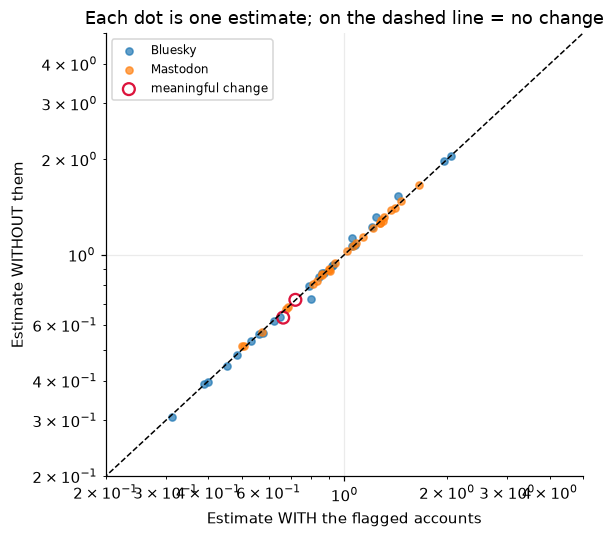

In [163]:
# How much do the flagged accounts change the results?  Refit the main model with them and without them, side by side.
OUT3 = ["likes", "reposts", "replies"]
_flags = ["has_link", "has_image", "has_video", "is_quote", "has_question", "has_hashtag", "has_mention"]
_rhs = " + ".join(_flags) + " + np.log1p(text_len) + sentiment + log_followers + log_age"
def _fit(d, o):
    d = d.astype({c: int for c in _flags})
    f = smf.glm(f"{o} ~ {_rhs}", data=d, family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(d["did"])[0]})
    return pd.DataFrame({"IRR": np.exp(f.params), "p": f.pvalues}).drop(["Intercept", "log_age", "log_followers"])
terms_ = _flags + ["np.log1p(text_len)", "sentiment"]
rows = []
for pl in COL:
    dp = both_all[both_all.platform == pl]
    for o in OUT3:
        w, wo = _fit(dp, o), _fit(dp[~dp.machine_regular], o)
        for t in terms_:
            rows.append(dict(platform=pl, outcome=o, term=t, irr_with=w.loc[t, "IRR"], irr_wo=wo.loc[t, "IRR"], p_with=w.loc[t, "p"], p_wo=wo.loc[t, "p"]))
bt = pd.DataFrame(rows)
bt["change_pct"] = 100 * (bt.irr_wo / bt.irr_with - 1)
bt["sig_flip"] = (bt.p_with < 0.05) != (bt.p_wo < 0.05)
bt["sign_flip"] = (bt.irr_with - 1) * (bt.irr_wo - 1) < 0
bt["meaningful"] = bt.sig_flip | bt.sign_flip | (bt.change_pct.abs() > 25)
print(f"{len(bt)} estimates compared (9 features x 3 outcomes x 2 platforms). Median change when the flagged accounts are removed: "
      f"{bt.change_pct.abs().median():.1f}%; largest: {bt.change_pct.abs().max():.0f}%.")
print(f"Meaningful changes (significance flips, sign flips, or more than 25% shift): {int(bt.meaningful.sum())}")
if bt.meaningful.any():
    display(bt[bt.meaningful][["platform", "outcome", "term", "irr_with", "irr_wo", "p_with", "p_wo"]].round(3))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0.1, 10], [0.1, 10], "k--", lw=1)
for pl in COL:
    s_ = bt[(bt.platform == pl) & ~bt.meaningful]; ax.scatter(s_.irr_with, s_.irr_wo, s=22, alpha=0.7, color=COL[pl], label=pl)
m_ = bt[bt.meaningful]; ax.scatter(m_.irr_with, m_.irr_wo, s=60, facecolor="none", edgecolor="crimson", lw=1.5, label="meaningful change")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.2, 5); ax.set_ylim(0.2, 5)
ax.set_xlabel("Estimate WITH the flagged accounts"); ax.set_ylabel("Estimate WITHOUT them"); ax.set_title("Each dot is one estimate; on the dashed line = no change"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Result.** Leaving out the 16 flagged accounts (1.8% of posts) changes the median estimate by 0.6% and the largest by 9%. Of 54 estimates compared, 2 are marked *meaningful*, and both are borderline significance flips with almost identical estimates (Bluesky reposts: @mention p = 0.056 vs 0.043; tone p = 0.049 vs 0.051). There are no sign flips and no change to any conclusion, so the default (bots left out) and `INCLUDE_BOTS = True` tell the same story. *Caveat:* the timestamp test misses bots that add random delays or react to events, and it flags some scheduled professional accounts that are not bots.

In [164]:
# Infer each human-like account's LOCAL clock from its quietest 6-hour window, assumed to be centred on 4 AM local time.
def quiet_offset(h):
    cnt = np.bincount(h, minlength=24).astype(float)
    win = np.array([cnt[[(s + k) % 24 for k in range(6)]].sum() for s in range(24)])
    s = int(np.argmin(win))
    return int(round((4 - (s + 2.5)) % 24)), win[s] / cnt.sum()          # hours to add to UTC, share of posts in the quiet window

hum = both[~both.machine_regular].copy()
off = {}
for did, g in hum.groupby("did"):
    if len(g) >= 30:
        o_, share = quiet_offset(g["hour"].astype(int).values)
        if share <= 0.12: off[did] = o_                                  # a uniform poster would have 25% in any 6 hours
hum["local_hour"] = (hum["hour"] + hum["did"].map(off)) % 24
use = hum.dropna(subset=["local_hour"]).copy(); use["local_hour"] = use["local_hour"].astype(int)
print(f"local time inferred for {use.did.nunique()} of {hum.did.nunique()} human-like accounts "
      f"({use.groupby('platform').did.nunique().to_dict()}); the rest post too evenly or too rarely")

local time inferred for 447 of 703 human-like accounts ({'Bluesky': 297, 'Mastodon': 150}); the rest post too evenly or too rarely


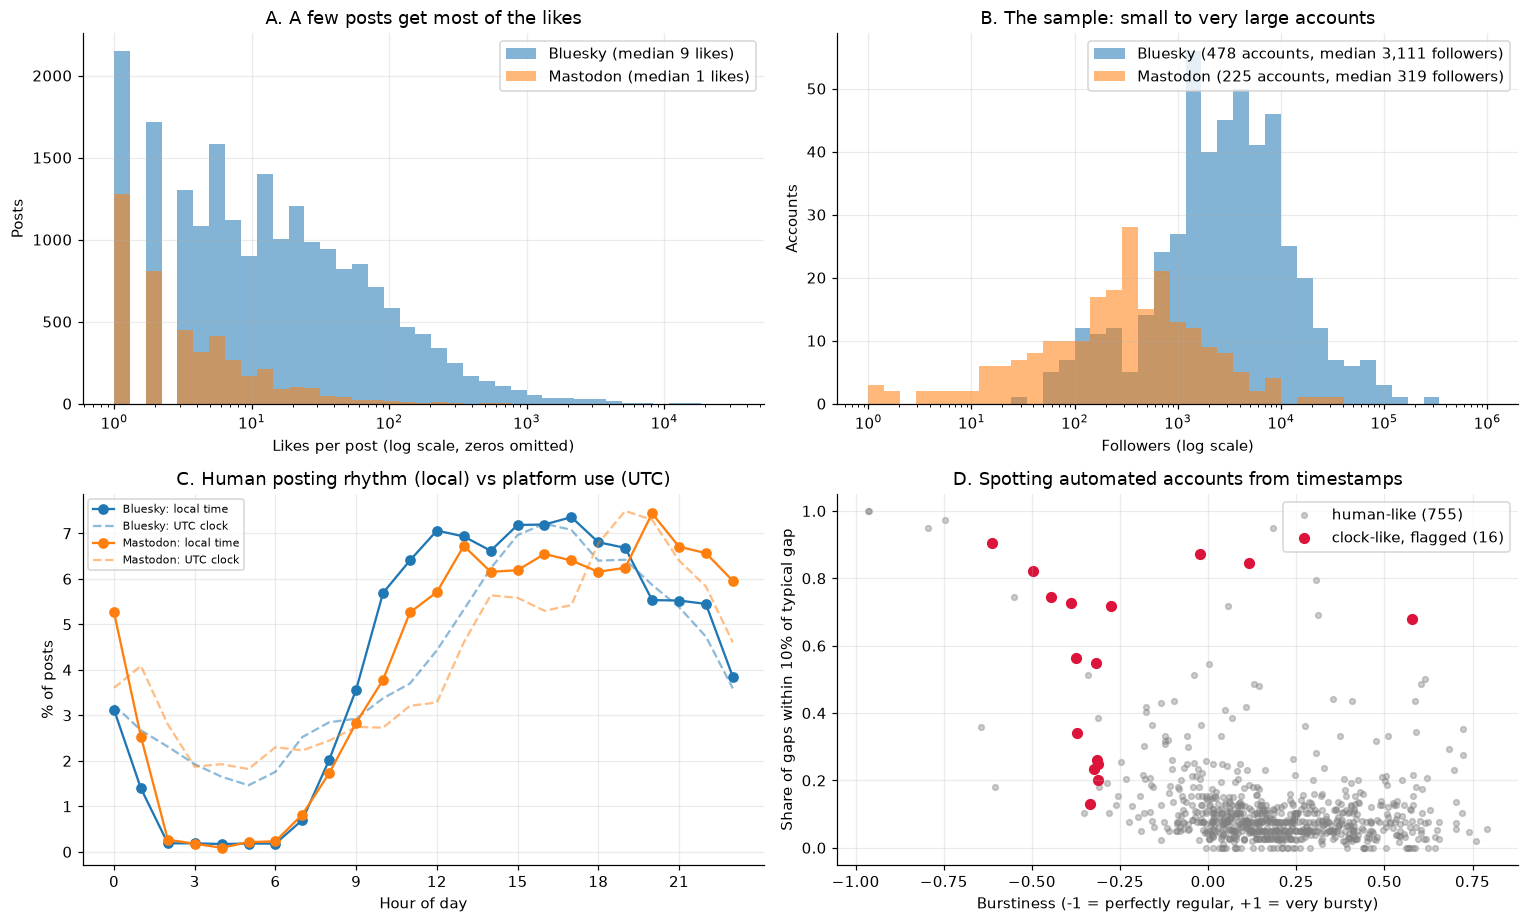

In [165]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
# A: how skewed is engagement? (log-spaced histogram of likes per post)
ax = axes[0, 0]
bins = np.logspace(0, 4.5, 40)
for pl in COL:
    v = both.loc[both.platform == pl, "likes"]; v = v[v > 0]
    ax.hist(v, bins=bins, alpha=0.55, color=COL[pl], label=f"{pl} (median {int(both.loc[both.platform == pl, 'likes'].median())} likes)")
ax.set_xscale("log"); ax.set_xlabel("Likes per post (log scale, zeros omitted)"); ax.set_ylabel("Posts")
ax.set_title("A. A few posts get most of the likes"); ax.legend()
# B: how big are the accounts?
ax = axes[0, 1]
bins = np.logspace(0, 6, 40)
for pl in COL:
    a = both[both.platform == pl].drop_duplicates("did")["followers"]
    ax.hist(a, bins=bins, alpha=0.55, color=COL[pl], label=f"{pl} ({len(a)} accounts, median {int(a.median()):,} followers)")
ax.set_xscale("log"); ax.set_xlabel("Followers (log scale)"); ax.set_ylabel("Accounts")
ax.set_title("B. The sample: small to very large accounts"); ax.legend()
# C: human rhythm (each person's LOCAL time, solid) vs platform use on the UTC clock (dashed)
ax = axes[1, 0]
for pl in COL:
    d_ = use[use.platform == pl]
    v = d_["local_hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    u = d_["hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    ax.plot(range(24), 100 * v.values, marker="o", color=COL[pl], label=f"{pl}: local time")
    ax.plot(range(24), 100 * u.values, ls="--", color=COL[pl], alpha=0.5, label=f"{pl}: UTC clock")
ax.set_xlabel("Hour of day"); ax.set_ylabel("% of posts"); ax.set_xticks(range(0, 24, 3))
ax.set_title("C. Human posting rhythm (local) vs platform use (UTC)"); ax.legend(fontsize=7)
# D: the timestamp bot test: clock-like accounts stand out
ax = axes[1, 1]
rs = pd.DataFrame(REGSTATS, index=["burstiness", "near_typical_gap"]).T
rs["flag"] = rs.index.isin(set(both_all.loc[both_all.machine_regular, "did"]))
ax.scatter(rs.loc[~rs.flag, "burstiness"], rs.loc[~rs.flag, "near_typical_gap"], s=14, alpha=0.4, color="gray", label=f"human-like ({(~rs.flag).sum()})")
ax.scatter(rs.loc[rs.flag, "burstiness"], rs.loc[rs.flag, "near_typical_gap"], s=40, color="crimson", label=f"clock-like, flagged ({rs.flag.sum()})")
ax.set_xlabel("Burstiness (-1 = perfectly regular, +1 = very bursty)"); ax.set_ylabel("Share of gaps within 10% of typical gap")
ax.set_title("D. Spotting automated accounts from timestamps"); ax.legend()
plt.tight_layout(); plt.show()

### Where in the world?
Neither network reports country. Language is a rough hint: each region's daytime hump falls at a different UTC hour, so a global audience would show separate language-specific peaks. Plotted from all collected posts (not just English), flagged accounts included.

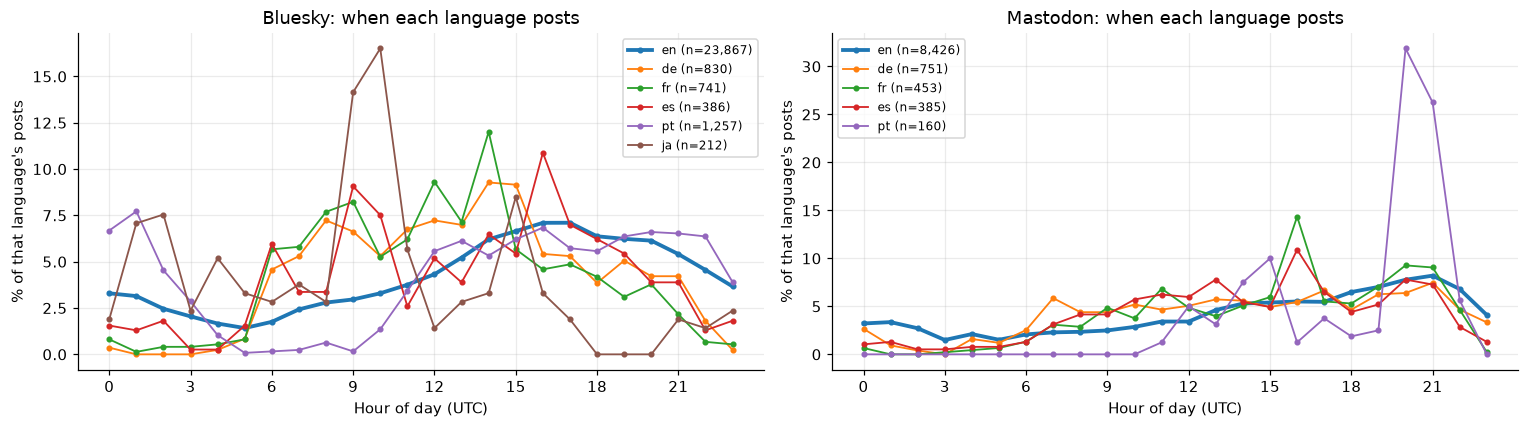

{'Bluesky': 'English = 70% of posts, no language tag = 18%', 'Mastodon': 'English = 77% of posts, no language tag = 0%'}


In [166]:
# Where in the world? Posting hour (UTC) by language: each region's daytime hump sits at a different UTC hour
raw_all = pd.concat([bsky_raw.assign(platform="Bluesky"), masto_raw.assign(platform="Mastodon")], ignore_index=True)
raw_all["h"] = pd.to_datetime(raw_all["created_at"], utc=True, errors="coerce").dt.hour
raw_all["lang2"] = raw_all["lang"].fillna("untagged").str[:2]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, pl in zip(axes, COL):
    d_ = raw_all[raw_all.platform == pl]; top = d_.lang2.value_counts()
    for l in [l for l in ["en", "de", "fr", "es", "pt", "ja"] if top.get(l, 0) >= 150]:
        v = d_[d_.lang2 == l]["h"].value_counts(normalize=True).reindex(range(24), fill_value=0)
        ax.plot(range(24), 100 * v.values, marker="o", ms=3, lw=2.5 if l == "en" else 1.2, label=f"{l} (n={top[l]:,})")
    ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("Hour of day (UTC)"); ax.set_ylabel("% of that language's posts")
    ax.set_title(f"{pl}: when each language posts"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print({pl: f"English = {100 * (raw_all[raw_all.platform == pl].lang2 == 'en').mean():.0f}% of posts, no language tag = {100 * raw_all[raw_all.platform == pl]['lang'].isna().mean():.0f}%" for pl in COL})

## 5. Do post formats differ?
Each format relative to a plain text post on the same platform (1× = same). Raw averages are in the table under the chart.

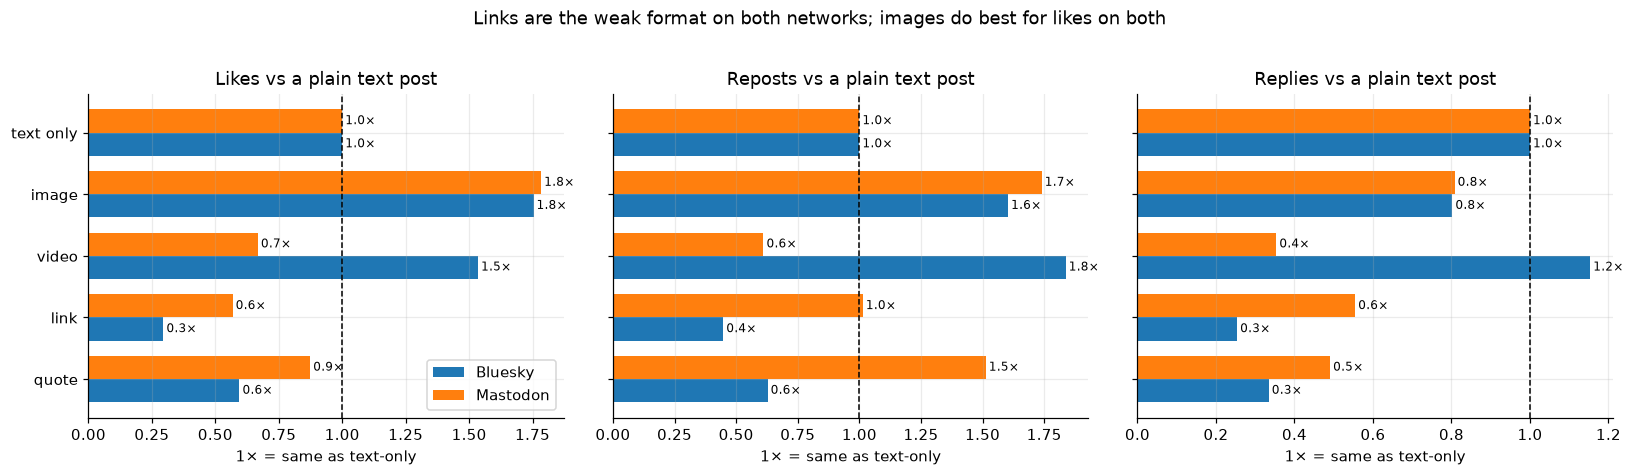

posts  mean_likes  mean_reposts  mean_replies  \
platform format                                                     
Bluesky  image       9592       98.64         15.35          2.68   
         link        5039       16.62          4.28          0.85   
         quote       2561       33.47          6.01          1.12   
         text only   3513       56.25          9.57          3.34   
         video       2212       86.34         17.58          3.85   
Mastodon image       1772        9.48          3.86          0.60   
         link        1971        3.02          2.25          0.41   
         quote        409        4.64          3.36          0.37   
         text only   2335        5.31          2.22          0.75   
         video        261        3.55          1.36          0.26   

                    pct_any_reply  
platform format                    
Bluesky  image               52.3  
         link                30.2  
         quote               36.0  
         text only           55.6  
         video               63.4  
Mastodon image               32.3  
         link                24.8  
         quote               23.5  
         text only           41.5  
         video               17.6

In [167]:
order = ["text only", "image", "video", "link", "quote"]
tbl = (both.groupby(["platform", "format"])
           .agg(posts=("likes", "size"), mean_likes=("likes", "mean"), mean_reposts=("reposts", "mean"),
                mean_replies=("replies", "mean"), pct_any_reply=("got_reply", "mean")))
tbl["pct_any_reply"] = (100 * tbl["pct_any_reply"]).round(1)

means = both.groupby(["format", "platform"])[["likes", "reposts", "replies"]].mean()
rel = means / means.xs("text only", level="format")           # relative to text-only, per platform
rel = rel.unstack("platform")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, m in zip(axes, ["likes", "reposts", "replies"]):
    r = rel[m].reindex(order[::-1])
    r.plot.barh(ax=ax, color=[COL[c] for c in r.columns], width=0.75, legend=False)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f×", fontsize=8, padding=2)
    ax.axvline(1, color="k", lw=1, ls="--")
    ax.set_title(f"{m.capitalize()} vs a plain text post"); ax.set_ylabel(""); ax.set_xlabel("1× = same as text-only")
axes[0].legend(title=None, loc="lower right")
plt.suptitle("Links are the weak format on both networks; images do best for likes on both", y=1.02)
plt.tight_layout(); plt.show()
tbl.round(2)

### Length
Both platforms on the **same character bins**, up to Bluesky's 300-character cap, each relative to the platform average.

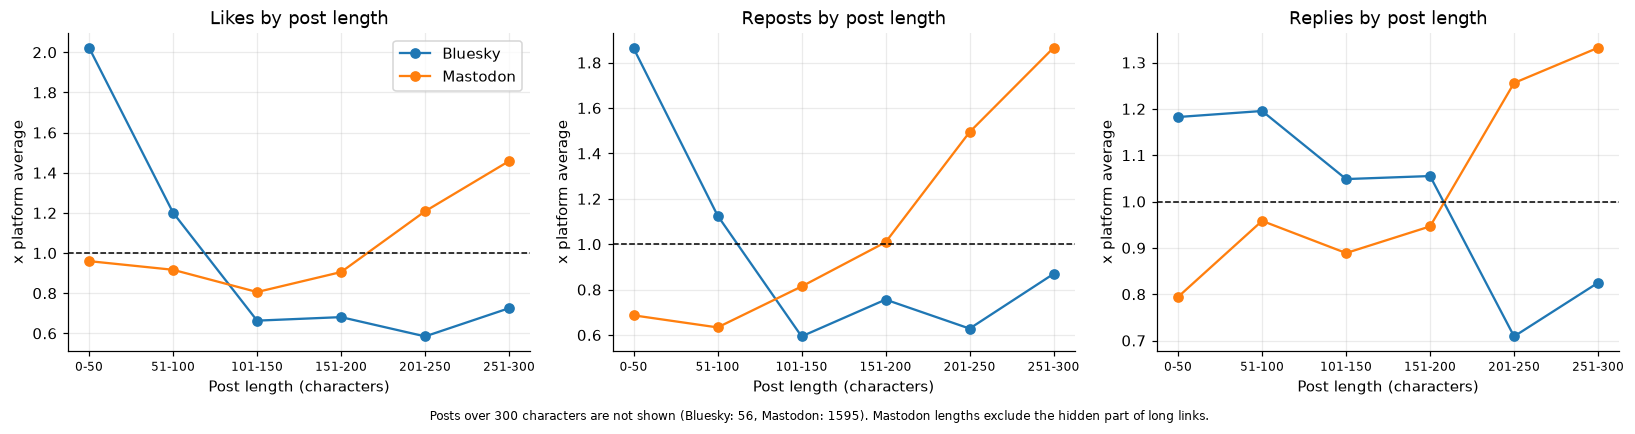

In [168]:
# Same character bins on both platforms, up to Bluesky's 300-character cap (Mastodon posts over 300 are left out here)
OUT3 = ["likes", "reposts", "replies"]
labs = ["0-50", "51-100", "101-150", "151-200", "201-250", "251-300"]
sh = both[both.text_len <= 300].copy()
sh["lbin"] = pd.cut(sh.text_len, bins=[-1, 50, 100, 150, 200, 250, 300], labels=labs)
by_len = sh.groupby(["platform", "lbin"], observed=True)[OUT3].mean() / sh.groupby("platform")[OUT3].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, m in zip(axes, OUT3):
    for pl in COL:
        ax.plot(range(6), by_len.loc[pl, m].reindex(labs).values, marker="o", color=COL[pl], label=pl)
    ax.axhline(1, color="k", lw=1, ls="--"); ax.set_xticks(range(6)); ax.set_xticklabels(labs, fontsize=8)
    ax.set_xlabel("Post length (characters)"); ax.set_ylabel("x platform average"); ax.set_title(f"{m.capitalize()} by post length")
axes[0].legend()
over = {pl: int(((both.platform == pl) & (both.text_len > 300)).sum()) for pl in COL}
fig.text(0.5, -0.02, f"Posts over 300 characters are not shown (Bluesky: {over['Bluesky']}, Mastodon: {over['Mastodon']}). Mastodon lengths exclude the hidden part of long links.", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

## 6. Scale: followers versus engagement
Each dot is an account (log-log). A slope below 1 means engagement grows more slowly than audience.

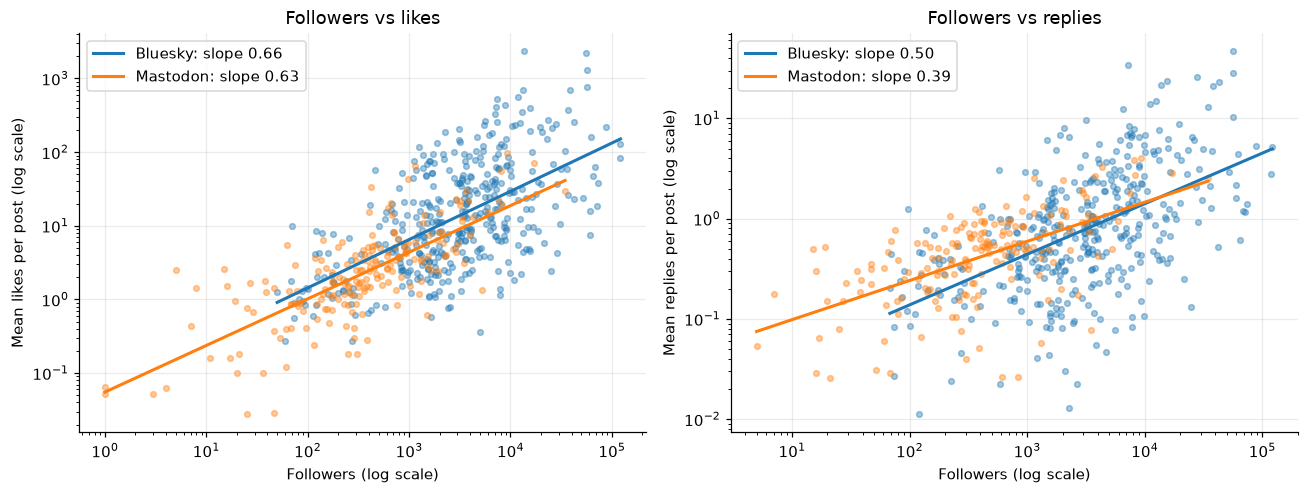

In [169]:
acct = both.groupby(["platform", "did"]).agg(followers=("followers", "first"), likes=("likes", "mean"),
                                              replies=("replies", "mean"), posts=("likes", "size"))
acct = acct[acct["posts"] >= 10]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, m in zip(axes, ["likes", "replies"]):
    for pl in COL:
        a = acct.loc[pl]; a = a[a[m] > 0]
        x, y = np.log10(a["followers"]), np.log10(a[m])
        b, c0 = np.polyfit(x, y, 1)
        ax.scatter(a["followers"], a[m], s=14, alpha=0.4, color=COL[pl])
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(10**xs, 10**(c0 + b * xs), color=COL[pl], lw=2, label=f"{pl}: slope {b:.2f}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Followers (log scale)"); ax.set_ylabel(f"Mean {m} per post (log scale)")
    ax.set_title(f"Followers vs {m}"); ax.legend()
plt.tight_layout(); plt.show()

## 7. Isolating post fitness
A Poisson regression estimates each feature **holding the others, tone, followers and post age fixed**. A filled dot means the result is statistically solid.

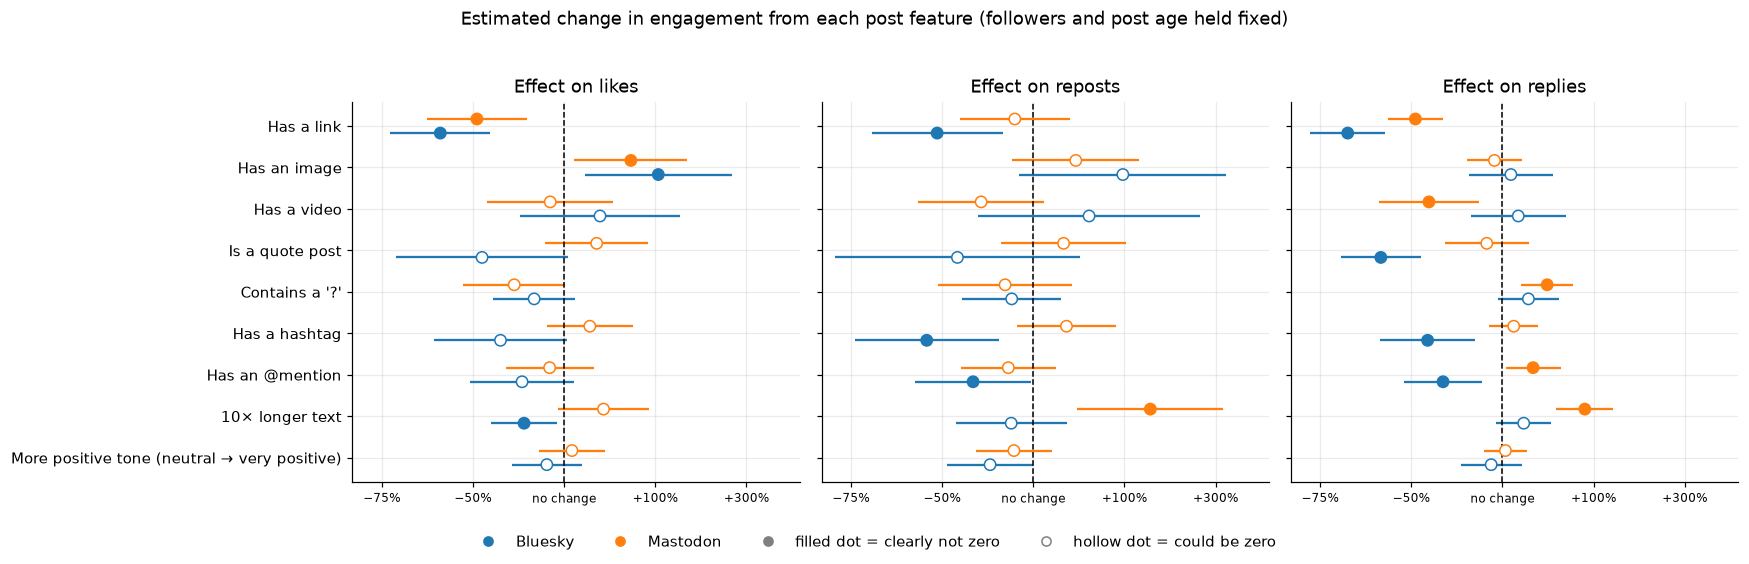

In [170]:
flags = ["has_link", "has_image", "has_video", "is_quote", "has_question", "has_hashtag", "has_mention"]
rhs = " + ".join(flags) + " + np.log1p(text_len) + sentiment + log_followers + log_age"
LEN = "np.log1p(text_len)"

def fit_irr(d, outcome):
    d = d.astype({c: int for c in flags})
    f = smf.glm(f"{outcome} ~ {rhs}", data=d, family=sm.families.Poisson()).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["did"])[0]})
    ci = f.conf_int()
    out = pd.DataFrame({"IRR": np.exp(f.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]),
                        "p": f.pvalues}).drop("Intercept")
    out.loc[LEN, ["IRR", "lo", "hi"]] = out.loc[LEN, ["IRR", "lo", "hi"]].astype(float) ** np.log(10)   # per 10x longer text
    return out

OUTCOMES = ["likes", "reposts", "replies"]
res = {(pl, o): fit_irr(both[both.platform == pl], o) for pl in COL for o in OUTCOMES}

LABELS = {"has_link": "Has a link", "has_image": "Has an image", "has_video": "Has a video",
          "is_quote": "Is a quote post", "has_question": "Contains a '?'", "has_hashtag": "Has a hashtag",
          "has_mention": "Has an @mention", LEN: "10× longer text",
          "sentiment": "More positive tone (neutral → very positive)"}
terms = list(LABELS)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, o in zip(axes, OUTCOMES):
    for off, pl in zip([-0.17, 0.17], COL):
        r = res[(pl, o)].loc[terms]
        y = np.arange(len(terms))[::-1] + off
        solid = (r["lo"] > 1) | (r["hi"] < 1)
        ax.hlines(y, r["lo"], r["hi"], color=COL[pl], lw=1.5)
        ax.scatter(r["IRR"], y, s=55, zorder=3, edgecolor=COL[pl],
                   facecolor=[COL[pl] if s else "white" for s in solid], label=pl)
    ax.axvline(1, color="k", lw=1, ls="--"); ax.set_xscale("log"); ax.set_xlim(0.2, 6)
    ticks = [0.25, 0.5, 1, 2, 4]
    ax.set_xticks(ticks); ax.set_xticklabels(["−75%", "−50%", "no change", "+100%", "+300%"], fontsize=8)
    ax.minorticks_off()
    ax.set_yticks(np.arange(len(terms))[::-1]); ax.set_yticklabels([LABELS[t] for t in terms])
    ax.set_title(f"Effect on {o}")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color=COL["Bluesky"], label="Bluesky"),
           Line2D([], [], marker="o", ls="", color=COL["Mastodon"], label="Mastodon"),
           Line2D([], [], marker="o", ls="", mfc="gray", mec="gray", label="filled dot = clearly not zero"),
           Line2D([], [], marker="o", ls="", mfc="white", mec="gray", label="hollow dot = could be zero")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False)
plt.suptitle("Estimated change in engagement from each post feature (followers and post age held fixed)", y=1.0)
plt.tight_layout(rect=(0, 0.07, 1, 0.97)); plt.show()

In [171]:
# the same results as a table (* = p < 0.05), plus how strongly audience size scales engagement
star = lambda r: f"{r.IRR:.2f}" + ("*" if r.p < 0.05 else "")
tab = pd.DataFrame({(o, pl): {LABELS[t]: star(res[(pl, o)].loc[t]) for t in terms}
                    for o in OUTCOMES for pl in COL})
print("IRR (1.00 = no change; * p<0.05)")
display(tab)
for pl in COL:
    print(pl, "| engagement ~ followers^b, b =",
          {o: round(float(np.log(res[(pl, o)].loc['log_followers', 'IRR'])), 2) for o in OUTCOMES})

IRR (1.00 = no change; * p<0.05)


likes          reposts  \
                                             Bluesky Mastodon Bluesky   
Has a link                                     0.39*    0.52*   0.48*   
Has an image                                   2.05*    1.66*    1.98   
Has a video                                     1.31     0.90    1.53   
Is a quote post                                 0.54     1.28    0.56   
Contains a '?'                                  0.80     0.68    0.85   
Has a hashtag                                   0.62     1.22   0.45*   
Has an @mention                                 0.73     0.90   0.63*   
10× longer text                                0.74*     1.35    0.85   
More positive tone (neutral → very positive)    0.88     1.06    0.72   

                                                      replies           
                                             Mastodon Bluesky Mastodon  
Has a link                                       0.87   0.31*    0.52*  
Has an image                                     1.38    1.07     0.94  
Has a video                                      0.67    1.13    0.57*  
Is a quote post                                  1.26   0.40*     0.89  
Contains a '?'                                   0.81    1.22    1.41*  
Has a hashtag                                    1.29   0.57*     1.09  
Has an @mention                                  0.83   0.64*    1.26*  
10× longer text                                 2.44*    1.18    1.87*  
More positive tone (neutral → very positive)     0.86    0.92     1.02

Bluesky | engagement ~ followers^b, b = {'likes': 0.79, 'reposts': 0.85, 'replies': 0.66}
Mastodon | engagement ~ followers^b, b = {'likes': 0.74, 'reposts': 0.81, 'replies': 0.47}


## 8. A second opinion on tone and topic: an AI labeler
Tone and topic are different things: calm words about a heated subject are neutral *wording* on a *charged topic*. I hand-labeled 52 posts, then tested a simple word-list scorer (VADER) and Claude Haiku 5.5 against my labels. Haiku then labeled the whole dataset (details below).

<details>
<summary><b>How the AI labeling worked</b> (click to expand)</summary>

Each post, plus the context a human sees (author bio, quoted post, image alt text, link-card text), went to `claude-haiku-5-5` at low effort with a fixed JSON schema (wording: positive/negative/neutral/mixed/unclear; charged_topic: true/false/unclear). About 30,000 posts were labeled through the Batch API (half price, roughly $1.4 total). Only post IDs and labels are stored, never post text. Caveats: n = 52 for validation, one labeler, one untuned prompt; the charged-topic label is noisy (88% agreement), which tends to shrink real differences.

</details>

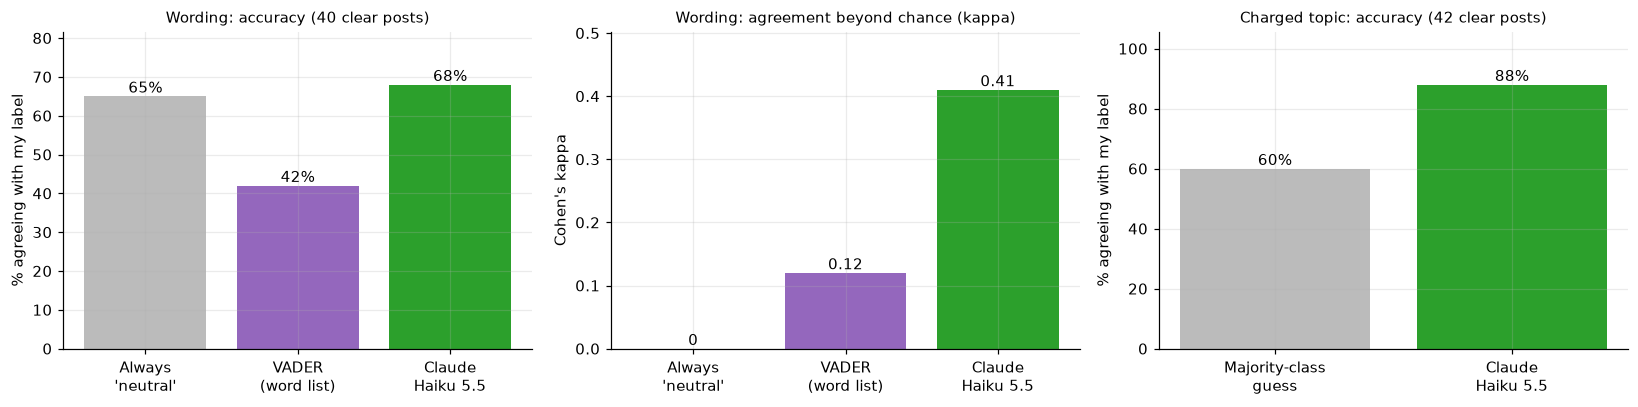

In [172]:
# Pilot: how well do the labelers agree with ME on 52 posts I hand-labeled? (labels are not shared, to protect the authors)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
names = ["Always\n'neutral'", "VADER\n(word list)", "Claude\nHaiku 5.5"]; cols = ["#bbbbbb", "#9467bd", "#2ca02c"]
for ax, vals, ttl, yl in [(axes[0], [65, 42, 68], "Wording: accuracy (40 clear posts)", "% agreeing with my label"),
                          (axes[1], [0.00, 0.12, 0.41], "Wording: agreement beyond chance (kappa)", "Cohen's kappa"),
                          (axes[2], [60, None, 88], "Charged topic: accuracy (42 clear posts)", "% agreeing with my label")]:
    xs = [n for n, v in zip(names, vals) if v is not None]; vs = [v for v in vals if v is not None]
    ax.bar(xs, vs, color=[c for c, v in zip(cols, vals) if v is not None])
    for i, v in enumerate(vs): ax.text(i, v, f"{v:g}" + ("" if "kappa" in ttl else "%"), ha="center", va="bottom")
    ax.set_title(ttl, fontsize=10); ax.set_ylabel(yl); ax.set_ylim(0, max(vs) * 1.2 + 0.01)
axes[2].set_xticks(range(2)); axes[2].set_xticklabels(["Majority-class\nguess", "Claude\nHaiku 5.5"])
plt.tight_layout(); plt.show()

In [173]:
lab_file = f"{DATA}/post_labels.csv"
HAVE_LABELS = os.path.exists(lab_file)
if HAVE_LABELS:
    lab = pd.read_csv(lab_file, dtype=str)
    lab["platform"] = lab["platform"].str.capitalize()
    both = both.merge(lab.rename(columns={"wording": "llm_wording"})[["platform", "post_id", "llm_wording", "charged_topic"]],
                      on=["platform", "post_id"], how="left")
    both["hot"] = both["charged_topic"].map({"true": 1, "false": 0})        # 'unclear' stays missing
    print(f"labels attached to {both['hot'].notna().sum():,} of {len(both):,} posts "
          f"({100 * both['hot'].mean():.0f}% of labeled posts are about charged topics)")
else:
    print("no post_labels.csv found: the topic sections below are skipped")

labels attached to 28,420 of 29,665 posts (29% of labeled posts are about charged topics)


### How common are charged topics?

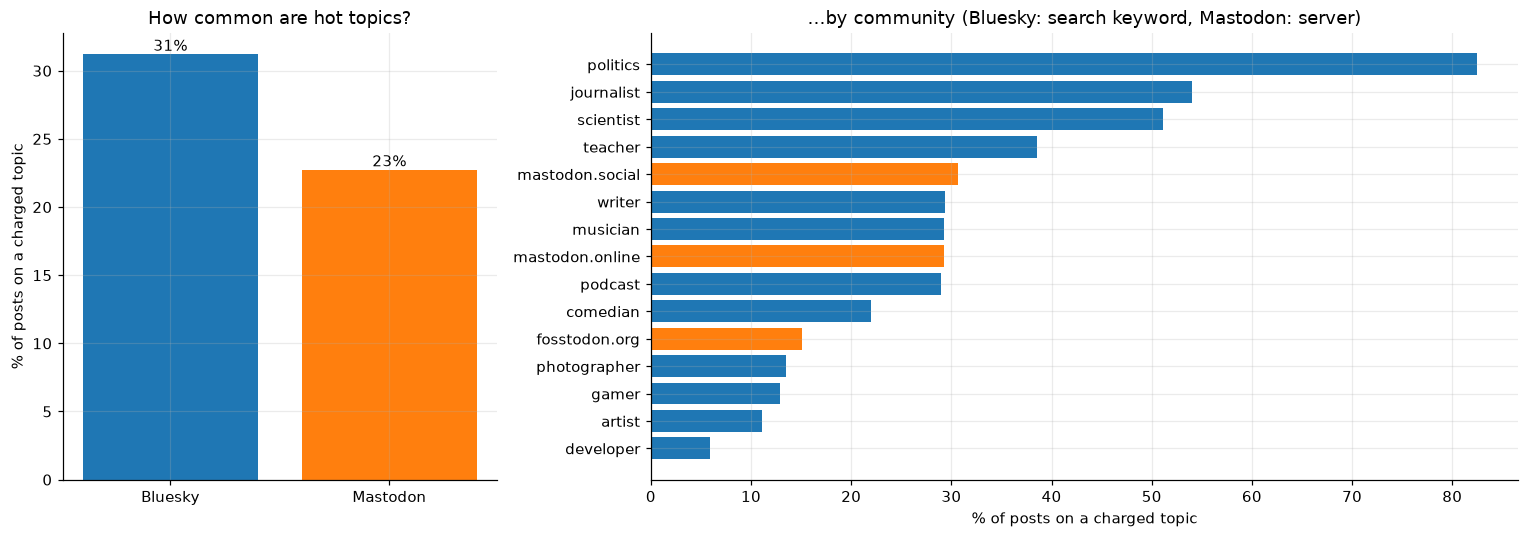

In [174]:
lab_both = both[both["hot"].notna()].copy(); lab_both["hot"] = lab_both["hot"].astype(int)
comm = lab_both.groupby(["platform", "found_via"]).agg(share=("hot", "mean"), n=("hot", "size")).reset_index()
comm = comm[comm.n >= 100].sort_values("share")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2]})
pl_share = lab_both.groupby("platform")["hot"].mean() * 100
axes[0].bar(pl_share.index, pl_share.values, color=[COL[p] for p in pl_share.index])
for i, v in enumerate(pl_share.values): axes[0].text(i, v, f"{v:.0f}%", ha="center", va="bottom")
axes[0].set_ylabel("% of posts on a charged topic"); axes[0].set_title("How common are hot topics?")
axes[1].barh([f"{c}" for c in comm.found_via], 100 * comm.share, color=[COL[p] for p in comm.platform])
axes[1].set_xlabel("% of posts on a charged topic"); axes[1].set_title("...by community (Bluesky: search keyword, Mastodon: server)")
plt.tight_layout(); plt.show()

## 9. Does post fitness survive hot topics and scale?
Three tests of robustness: (1) does a charged topic change engagement by itself; (2) does each feature keep working for small, mid and large accounts and for hot versus everyday topics; (3) comparing each post only with *its own author's average* (this removes everything about the account).

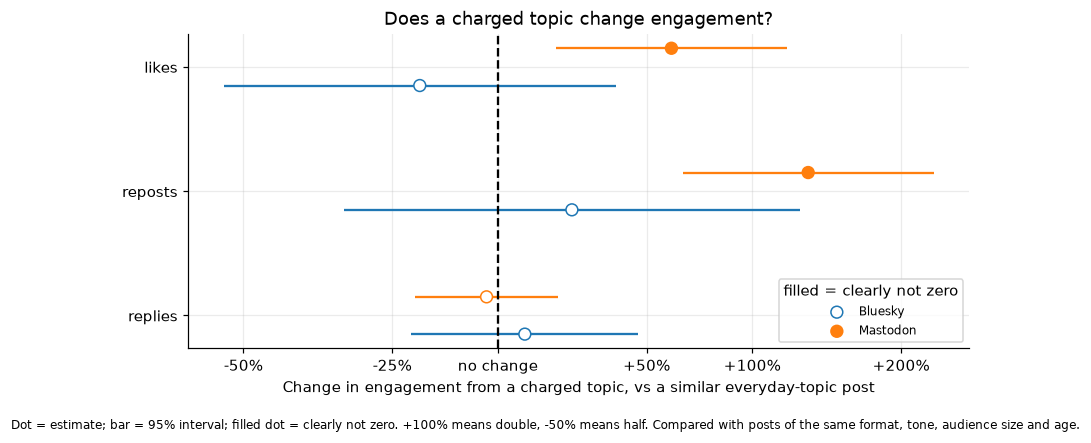

IRR     95% CI      p
Bluesky  likes    0.81  0.47-1.38  0.435
         reposts  1.22  0.66-2.28  0.524
         replies  1.08  0.79-1.47   0.64
Mastodon likes     1.6  1.17-2.20  0.003
         reposts  2.33  1.66-3.28    0.0
         replies  0.97  0.80-1.18  0.758

In [175]:
# Does a charged topic itself change engagement, holding format, tone, followers and age fixed?
def fit_any(d, y, rhs_, ln10_term=True):
    d = d.astype({c: int for c in flags if c in d})
    f = smf.glm(f"{y} ~ {rhs_}", data=d, family=sm.families.Poisson()).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["did"])[0]})
    ci = f.conf_int()
    out = pd.DataFrame({"IRR": np.exp(f.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p": f.pvalues}).drop("Intercept")
    if ln10_term and LEN in out.index: out.loc[LEN, ["IRR", "lo", "hi"]] = out.loc[LEN, ["IRR", "lo", "hi"]].astype(float) ** np.log(10)
    return out

rhs_hot = rhs + " + hot"
hot_fx = {(pl, o): fit_any(lab_both[lab_both.platform == pl], o, rhs_hot).loc["hot"] for pl in COL for o in OUTCOMES}
fig, ax = plt.subplots(figsize=(8, 3.8))
for off, pl in zip([-0.15, 0.15], COL):
    r = pd.DataFrame({o: hot_fx[(pl, o)] for o in OUTCOMES}).T
    y = np.arange(3)[::-1] + off; solid = (r["lo"] > 1) | (r["hi"] < 1)
    ax.hlines(y, r["lo"], r["hi"], color=COL[pl], lw=1.5)
    ax.scatter(r["IRR"], y, s=60, zorder=3, edgecolor=COL[pl], facecolor=[COL[pl] if s else "white" for s in solid], label=pl)
ax.axvline(1, color="k", ls="--"); ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3]); ax.set_xticklabels(["-50%", "-25%", "no change", "+50%", "+100%", "+200%"]); ax.minorticks_off()
ax.set_yticks(range(3)); ax.set_yticklabels(OUTCOMES[::-1]); ax.legend(title="filled = clearly not zero", loc="lower right", fontsize=8)
ax.set_xlabel("Change in engagement from a charged topic, vs a similar everyday-topic post")
ax.set_title("Does a charged topic change engagement?")
fig.text(0.5, -0.04, "Dot = estimate; bar = 95% interval; filled dot = clearly not zero. +100% means double, -50% means half. Compared with posts of the same format, tone, audience size and age.", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame({(pl, o): {"IRR": round(hot_fx[(pl, o)]["IRR"], 2), "95% CI": f"{hot_fx[(pl, o)]['lo']:.2f}-{hot_fx[(pl, o)]['hi']:.2f}", "p": round(hot_fx[(pl, o)]["p"], 3)} for pl in COL for o in OUTCOMES}).T)

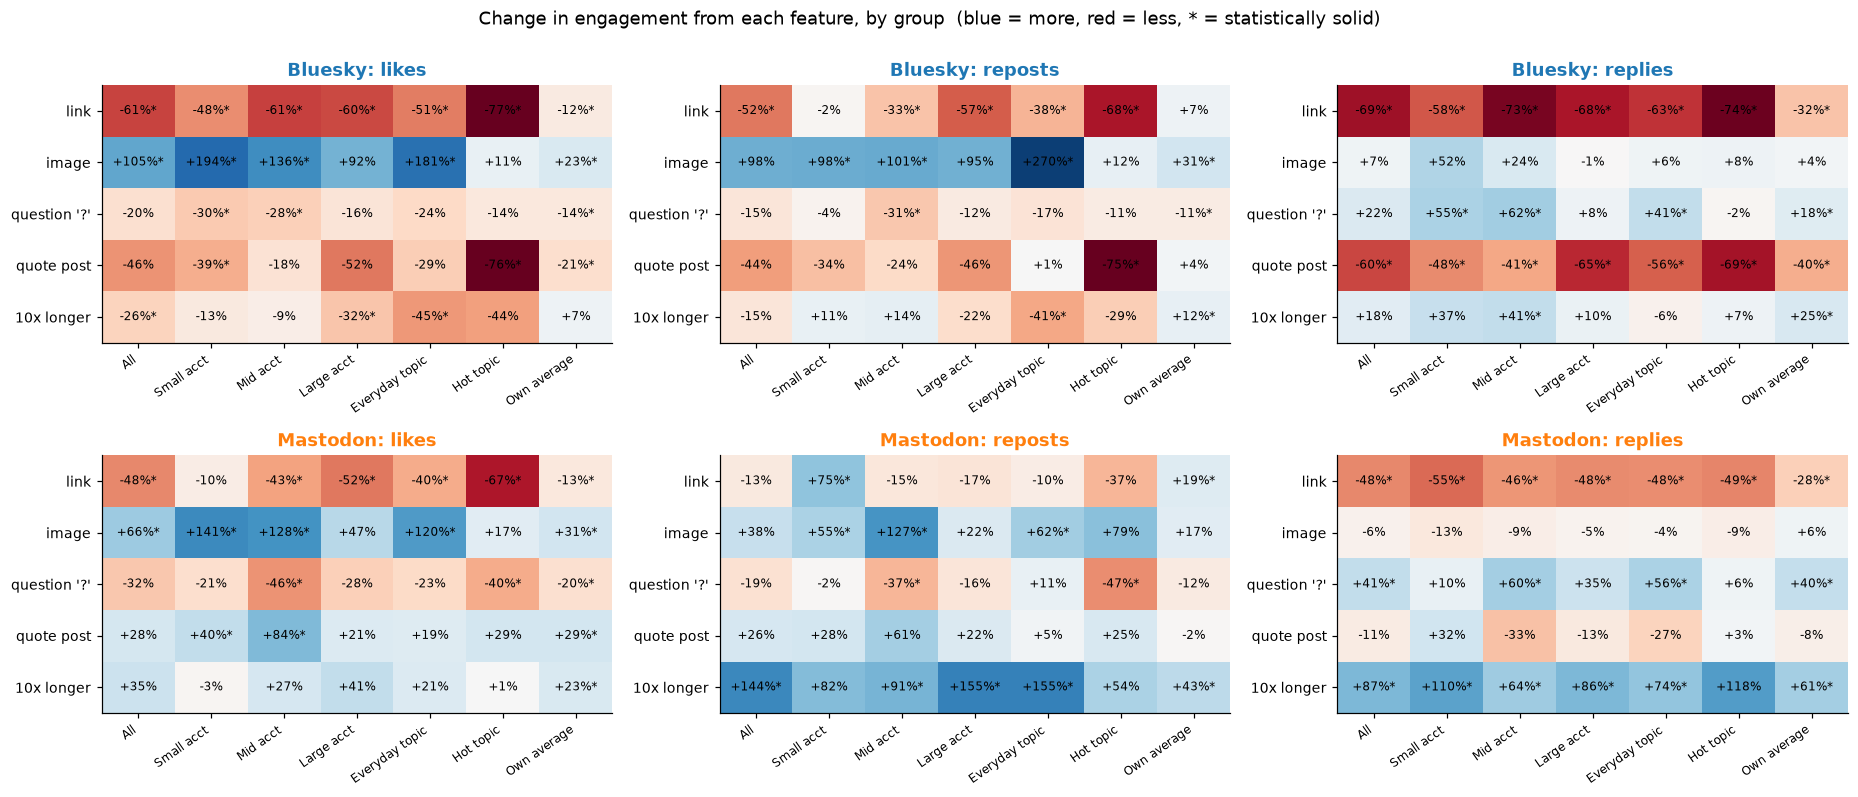

In [176]:
# Does each post feature keep working across account size and topic type?
KEY = ["has_link", "has_image", "has_question", "is_quote", LEN]
KLAB = {"has_link": "link", "has_image": "image", "has_question": "question '?'", "is_quote": "quote post", LEN: "10x longer"}
both["size"] = both.groupby("platform")["followers"].transform(lambda s: pd.qcut(s.rank(method="first"), 3, labels=["small", "mid", "large"]))
rhs_nof = rhs.replace(" + log_followers", "")
def fit_rel(d, o):                      # each post relative to ITS OWN author's average (compares posts within an account)
    d = d.copy(); m = d.groupby("did")[o].transform("mean"); d = d[m > 0].copy(); d["rel"] = d[o] / m[m > 0]
    return fit_any(d, "rel", rhs_nof)
STR = {"All": lambda d: d, "Small acct": lambda d: d[d["size"] == "small"], "Mid acct": lambda d: d[d["size"] == "mid"],
       "Large acct": lambda d: d[d["size"] == "large"], "Everyday topic": lambda d: d[d["hot"] == 0], "Hot topic": lambda d: d[d["hot"] == 1]}
grid = {}
for pl in COL:
    dp = both[both.platform == pl]
    for o in OUTCOMES:
        for s, fn in STR.items():
            try: grid[(pl, o, s)] = fit_any(fn(dp).dropna(subset=["hot"]) if "topic" in s else fn(dp), o, rhs)
            except Exception: grid[(pl, o, s)] = None
        try: grid[(pl, o, "Own average")] = fit_rel(dp, o)
        except Exception: grid[(pl, o, "Own average")] = None
COLS = list(STR) + ["Own average"]

fig, axes = plt.subplots(2, 3, figsize=(17, 7.2))
for r_i, pl in enumerate(COL):
    for c_i, o in enumerate(OUTCOMES):
        ax = axes[r_i, c_i]; M = np.full((len(KEY), len(COLS)), np.nan); T = [[""] * len(COLS) for _ in KEY]
        for j, s in enumerate(COLS):
            g = grid[(pl, o, s)]
            if g is None: continue
            for i, k in enumerate(KEY):
                irr = g.loc[k, "IRR"]; M[i, j] = np.log2(np.clip(irr, 0.25, 4))
                T[i][j] = f"{100 * (irr - 1):+.0f}%" + ("*" if g.loc[k, "p"] < 0.05 else "")
        ax.imshow(M, cmap="RdBu", vmin=-2, vmax=2, aspect="auto")
        for i in range(len(KEY)):
            for j in range(len(COLS)): ax.text(j, i, T[i][j], ha="center", va="center", fontsize=8)
        ax.set_xticks(range(len(COLS))); ax.set_xticklabels(COLS, rotation=35, ha="right", fontsize=8)
        ax.set_yticks(range(len(KEY))); ax.set_yticklabels([KLAB[k] for k in KEY], fontsize=9)
        ax.set_title(f"{pl}: {o}", color=COL[pl], fontweight="bold"); ax.grid(False)
plt.suptitle("Change in engagement from each feature, by group  (blue = more, red = less, * = statistically solid)", y=1.0)
plt.tight_layout(); plt.show()

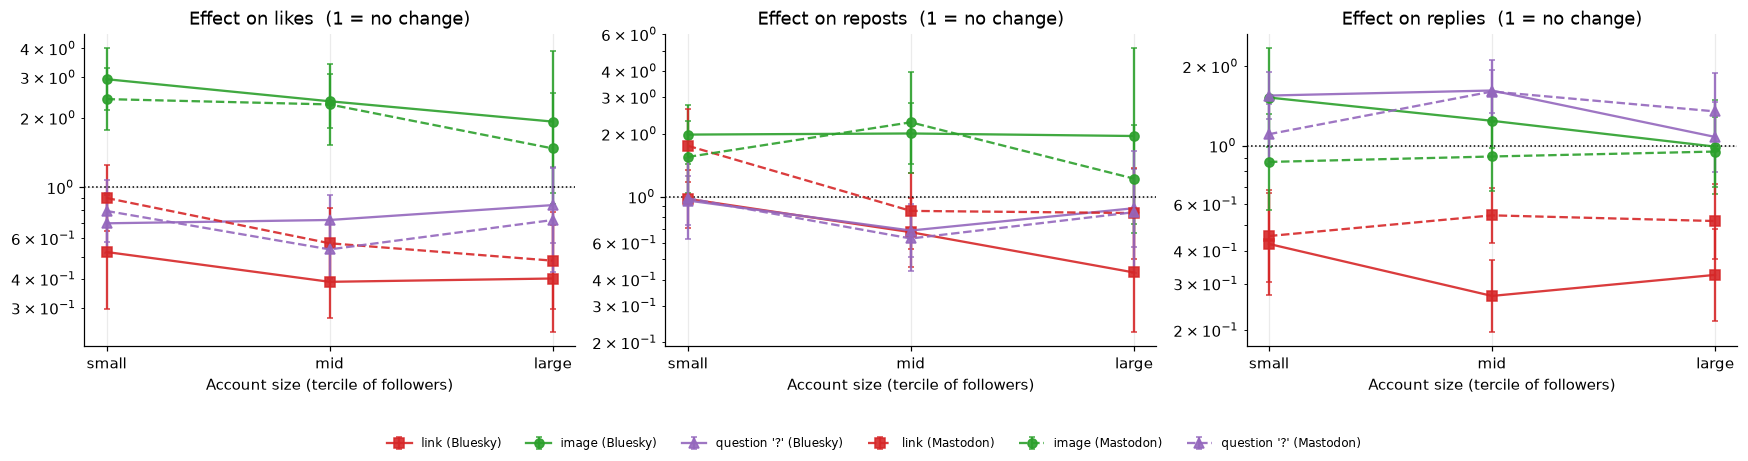

In [177]:
# The same story as lines: does the effect change from small to large accounts?
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=False)
sz = ["Small acct", "Mid acct", "Large acct"]
for ax, o in zip(axes, OUTCOMES):
    for pl, ls in zip(COL, ["-", "--"]):
        for k, mk, cl in [("has_link", "s", "#d62728"), ("has_image", "o", "#2ca02c"), ("has_question", "^", "#9467bd")]:
            rows = [grid[(pl, o, s)] for s in sz]
            if any(r is None for r in rows): continue
            y = [r.loc[k, "IRR"] for r in rows]; lo = [r.loc[k, "lo"] for r in rows]; hi = [r.loc[k, "hi"] for r in rows]
            ax.errorbar(range(3), y, yerr=[np.array(y) - lo, np.array(hi) - y], marker=mk, ls=ls, color=cl, alpha=0.9, capsize=2,
                        label=f"{KLAB[k]} ({pl})")
    ax.axhline(1, color="k", lw=1, ls=":"); ax.set_yscale("log"); ax.set_xticks(range(3)); ax.set_xticklabels(["small", "mid", "large"])
    ax.set_xlabel("Account size (tercile of followers)"); ax.set_title(f"Effect on {o}  (1 = no change)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=6, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

### Does the length effect agree on a common range?
Mastodon allows longer posts than Bluesky, so the length effect is refit on posts of 300 characters or fewer on both.

all posts <= 300 chars
Bluesky  likes       0.74*        0.74*
         reposts      0.85         0.85
         replies      1.18         1.18
Mastodon likes        1.35         1.40
         reposts     2.44*        2.58*
         replies     1.87*        1.58*

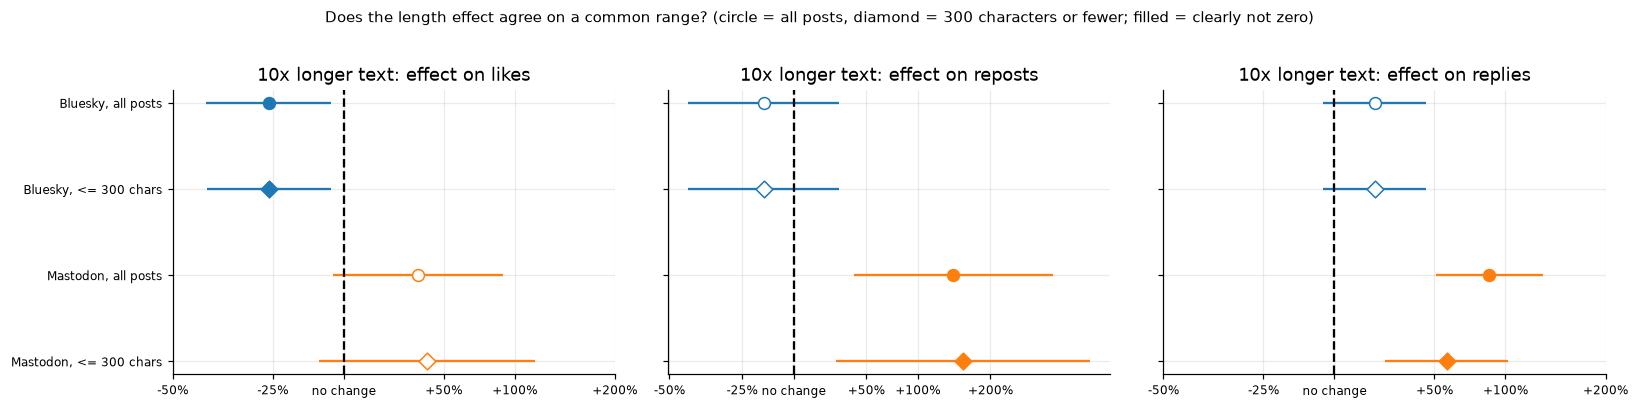

In [178]:
# Does the length effect agree once both platforms are compared on the SAME range (<= 300 characters)?
both_c = both[both.text_len <= 300]
cmp_len = {(pl, o, k): fit_any(d[d.platform == pl], o, rhs).loc[LEN]
           for k, d in [("all posts", both), ("<= 300 chars", both_c)] for pl in COL for o in OUTCOMES}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, o in zip(axes, OUTCOMES):
    for yi, (pl, k) in enumerate([(p, k) for p in COL for k in ("all posts", "<= 300 chars")][::-1]):
        r = cmp_len[(pl, o, k)]; solid = (r.lo > 1) or (r.hi < 1)
        ax.hlines(yi, r.lo, r.hi, color=COL[pl], lw=1.5)
        ax.scatter(r.IRR, yi, s=60, zorder=3, edgecolor=COL[pl], facecolor=COL[pl] if solid else "white", marker="o" if k == "all posts" else "D")
    ax.axvline(1, color="k", ls="--"); ax.set_xscale("log")
    ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3]); ax.set_xticklabels(["-50%", "-25%", "no change", "+50%", "+100%", "+200%"], fontsize=8); ax.minorticks_off()
    ax.set_yticks(range(4)); ax.set_yticklabels([f"{p}, {k}" for p in COL for k in ("all posts", "<= 300 chars")][::-1], fontsize=8)
    ax.set_title(f"10x longer text: effect on {o}")
star = lambda r: f"{r.IRR:.2f}" + ("*" if (r.lo > 1 or r.hi < 1) else "")
display(pd.DataFrame({(pl, o): {k: star(cmp_len[(pl, o, k)]) for k in ("all posts", "<= 300 chars")} for pl in COL for o in OUTCOMES}).T)
plt.suptitle("Does the length effect agree on a common range? (circle = all posts, diamond = 300 characters or fewer; filled = clearly not zero)", y=1.02, fontsize=10)
plt.tight_layout(); plt.show()

### Same author, or different authors?
Solid lines compare each post with its own author's average; dashed lines are the across-accounts pattern from above.

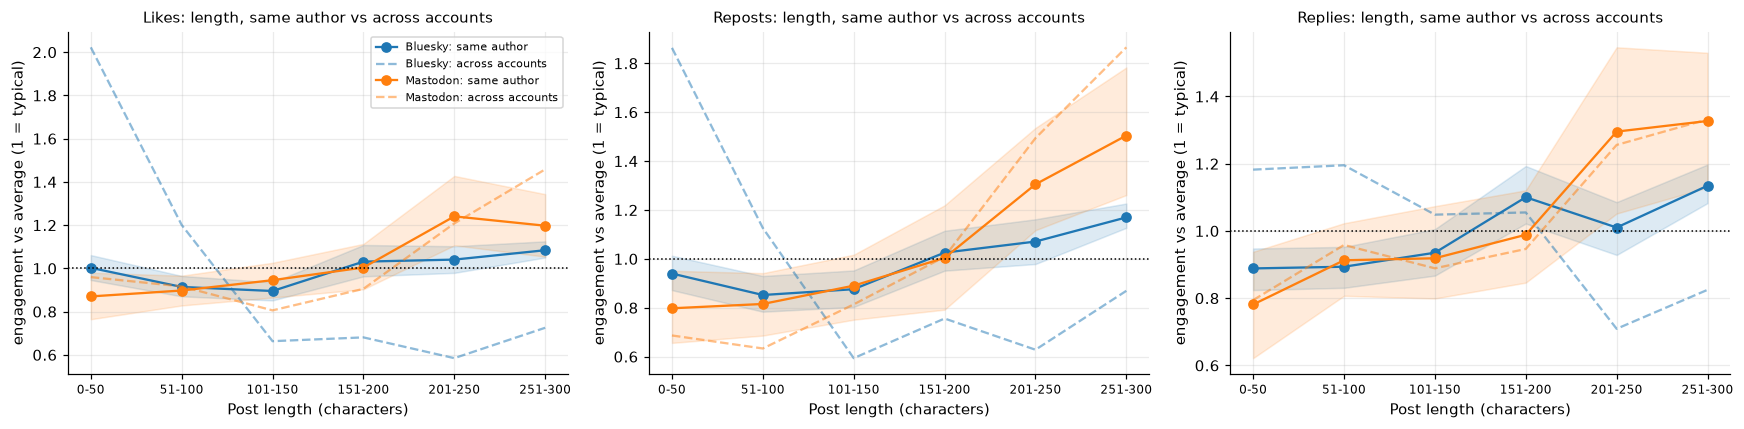

In [179]:
# Same author vs across authors: is the length pattern about the AUDIENCE'S taste, or about WHO writes short and long posts?
rng2 = np.random.default_rng(1)
def within_curve(d, o):
    m = d.groupby("did")[o].transform("mean"); k = m > 0; d = d[k].assign(rel=d.loc[k, o] / m[k])
    ids = d["did"].unique(); ix = d["did"].map({a: i for i, a in enumerate(ids)}).values; b = d["lbin"].cat.codes.values
    S = np.zeros((len(ids), 6)); N = np.zeros((len(ids), 6)); np.add.at(S, (ix, b), d["rel"].values); np.add.at(N, (ix, b), 1)
    B = rng2.integers(0, len(ids), (300, len(ids))); boot = S[B].sum(1) / np.maximum(N[B].sum(1), 1)
    return S.sum(0) / np.maximum(N.sum(0), 1), np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, o in zip(axes, OUTCOMES):
    for pl in COL:
        mu, lo, hi = within_curve(sh[sh.platform == pl], o)
        ax.plot(range(6), mu, marker="o", color=COL[pl], label=f"{pl}: same author"); ax.fill_between(range(6), lo, hi, color=COL[pl], alpha=0.15)
        ax.plot(range(6), by_len.loc[pl, o].reindex(labs).values, ls="--", color=COL[pl], alpha=0.5, label=f"{pl}: across accounts")
    ax.axhline(1, color="k", lw=1, ls=":"); ax.set_xticks(range(6)); ax.set_xticklabels(labs, fontsize=8)
    ax.set_xlabel("Post length (characters)"); ax.set_ylabel("engagement vs average (1 = typical)"); ax.set_title(f"{o.capitalize()}: length, same author vs across accounts", fontsize=10)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Finding (exploratory): the networks disagree on length across authors, but not within an author.** Comparing *accounts*, short posts earn more on Bluesky and long posts earn more on Mastodon (dashed lines). Comparing each post with *its own author's average* (solid lines), the pattern is much flatter on Bluesky and still upward on Mastodon, with no sign of a reversal. So the opposite pattern across accounts mostly reflects **who writes short versus long posts** (different kinds of accounts and posts), not a clear difference in what each audience wants. That rules out the simplest "two audiences, one prefers long-form" story, though other explanations (feed design, which communities were sampled) remain untested.

## 10. When to post: time of day
**Pre-specified (H-time):** engagement varies with the author's *local* hour, and posts made in the author's local night earn less than posts made in waking hours. Neither network reports local time, so it is inferred from each account's quietest 6-hour stretch (assumed to be about 4 AM local). Likes, reposts and replies are all analyzed. Any "best hour" is exploratory.

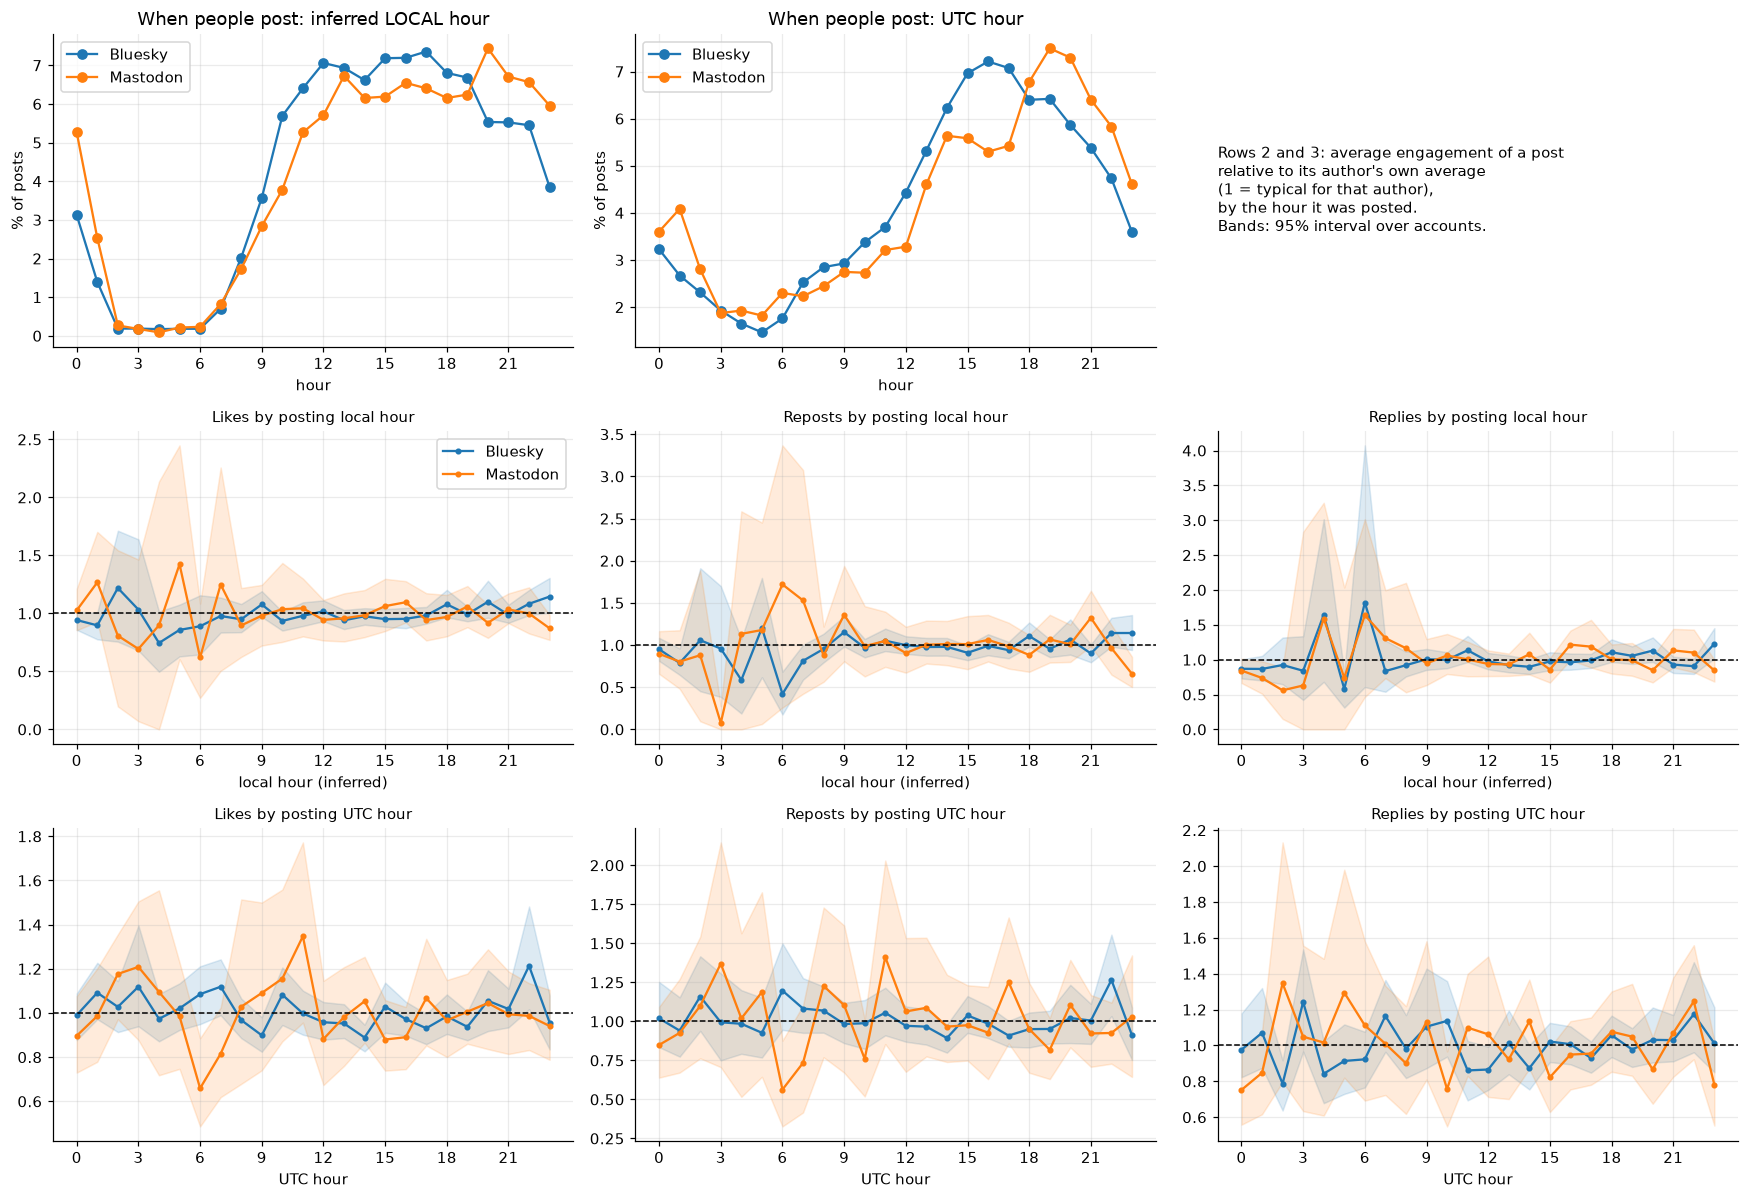

In [180]:
# When do people post (local time), and do posts at some hours earn more?  Each post is compared with its OWN author's average.
rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for pl in COL:
    d = use[use.platform == pl]
    vol = d["local_hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    axes[0, 0].plot(range(24), 100 * vol.values, marker="o", color=COL[pl], label=pl)
    voc = d["hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    axes[0, 1].plot(range(24), 100 * voc.values, marker="o", color=COL[pl], label=pl)
axes[0, 0].set_title("When people post: inferred LOCAL hour"); axes[0, 1].set_title("When people post: UTC hour")
for ax in axes[0, :2]: ax.set_xlabel("hour"); ax.set_ylabel("% of posts"); ax.set_xticks(range(0, 24, 3)); ax.legend()
axes[0, 2].axis("off")
axes[0, 2].text(0, 0.5, "Rows 2 and 3: average engagement of a post\nrelative to its author's own average\n(1 = typical for that author),\nby the hour it was posted.\nBands: 95% interval over accounts.", fontsize=10, va="center")
def hour_curve(d, o, col):
    m = d.groupby("did")[o].transform("mean"); k = m > 0; d = d[k].assign(rel=d.loc[k, o] / m[k])
    ids = d["did"].unique(); ix = {a: i for i, a in enumerate(ids)}
    S = np.zeros((len(ids), 24)); N = np.zeros((len(ids), 24))
    np.add.at(S, (d["did"].map(ix).values, d[col].values), d["rel"].values); np.add.at(N, (d["did"].map(ix).values, d[col].values), 1)
    B = rng.integers(0, len(ids), (300, len(ids)))
    boot = S[B].sum(1) / np.maximum(N[B].sum(1), 1)
    return S.sum(0) / np.maximum(N.sum(0), 1), np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
for r_i, (col, nm) in enumerate([("local_hour", "local hour (inferred)"), ("hour", "UTC hour")], start=1):
    for c_i, o in enumerate(OUTCOMES):
        ax = axes[r_i, c_i]
        for pl in COL:
            mu, lo, hi = hour_curve(use[use.platform == pl], o, col)
            ax.plot(range(24), mu, color=COL[pl], marker="o", ms=3, label=pl); ax.fill_between(range(24), lo, hi, color=COL[pl], alpha=0.15)
        ax.axhline(1, color="k", lw=1, ls="--"); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel(nm); ax.set_title(f"{o.capitalize()} by posting {nm.split(' (')[0]}", fontsize=10)
axes[1, 0].legend()
plt.tight_layout(); plt.show()

Joint test that time of day matters at all (p-value; small = it matters):


local hour  UTC hour
Bluesky  likes        0.1905    0.0000
         reposts      0.0008    0.0000
         replies      0.0361    0.0008
Mastodon likes        0.3330    0.5195
         reposts      0.5443    0.0462
         replies      0.1031    0.9454

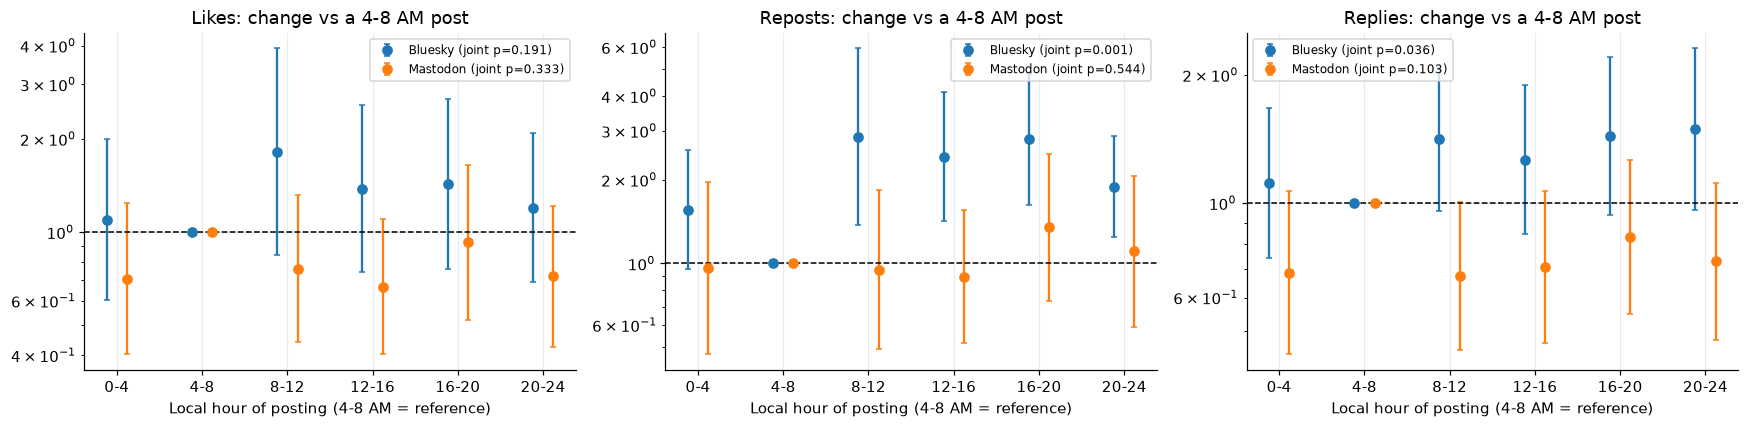

In [181]:
# Formal test: six 4-hour bins, holding format, tone, followers and post age fixed (reference bin = 4-8 AM)
def time_test(d, o, col):
    d = d.assign(tbin=(d[col] // 4).astype(int)).astype({c: int for c in flags})
    f = smf.glm(f"{o} ~ {rhs} + C(tbin, Treatment(reference=1))", data=d, family=sm.families.Poisson()).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["did"])[0]})
    wt = f.wald_test_terms(skip_single=False, scalar=True).table
    p = float(wt.loc[[i for i in wt.index if "tbin" in i][0], "pvalue"])
    ci = f.conf_int(); keep = [i for i in f.params.index if "tbin" in i]
    lv = [int(i.split("T.")[1].rstrip("]")) for i in keep]
    return p, pd.DataFrame({"IRR": np.exp(f.params[keep]).values, "lo": np.exp(ci.loc[keep, 0]).values, "hi": np.exp(ci.loc[keep, 1]).values}, index=lv)
tt = {}
for pl in COL:
    for o in OUTCOMES:
        for col in ("local_hour", "hour"):
            try: tt[(pl, o, col)] = time_test(use[use.platform == pl], o, col)
            except Exception as e: tt[(pl, o, col)] = (np.nan, None)
ptab = pd.DataFrame({(pl, o): {"local hour": tt[(pl, o, "local_hour")][0], "UTC hour": tt[(pl, o, "hour")][0]} for pl in COL for o in OUTCOMES}).T
print("Joint test that time of day matters at all (p-value; small = it matters):"); display(ptab.round(4))
BINS = ["0-4", "4-8", "8-12", "12-16", "16-20", "20-24"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, o in zip(axes, OUTCOMES):
    for off_, pl in zip([-0.12, 0.12], COL):
        p, r = tt[(pl, o, "local_hour")]
        if r is None: continue
        r = r.reindex(range(6)); r.loc[1] = [1, 1, 1]
        ax.errorbar(np.arange(6) + off_, r["IRR"], yerr=[r["IRR"] - r["lo"], r["hi"] - r["IRR"]], marker="o", color=COL[pl], capsize=2, ls="none", label=f"{pl} (joint p={p:.3f})")
    ax.axhline(1, color="k", ls="--", lw=1); ax.set_yscale("log"); ax.set_xticks(range(6)); ax.set_xticklabels(BINS)
    ax.set_xlabel("Local hour of posting (4-8 AM = reference)"); ax.set_title(f"{o.capitalize()}: change vs a 4-8 AM post"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 11. Conclusions
**Do the findings survive scale, topic and time?** The heatmap in section 9 and the charts in section 10 are the one-look answers.

| Question | Answer |
|---|---|
| **Does post fitness survive scale?** | **Mostly yes.** Signs stay the same from small to mid to large accounts. The link penalty is stable (Bluesky likes -48% / -61% / -60%); the image boost fades with size (+194% to +92%). Within the same author the signs hold but shrink (link: likes -12%, replies -32%; image: likes +23%). |
| **Does it survive hot vs everyday topics?** | **Partly.** The link penalty holds in both and is bigger on hot topics (Bluesky likes -77%). The **image and question advantages are everyday-topic effects**: image likes +181% vs +11% (Bluesky); question replies +41% vs -2% (Bluesky) and +56% vs +6% (Mastodon). |
| **Do hot topics themselves get more engagement?** | **Not replies** (Bluesky x1.08, Mastodon x0.97, neither clear). On **Mastodon**: **likes x1.60, reposts x2.33**. On Bluesky nothing clear. |
| **Does time of day matter? (H-time)** | **Partly, and only on Bluesky.** Joint tests by inferred local hour: Bluesky reposts p = 0.0008, replies p = 0.036, likes p = 0.19; Mastodon all p > 0.10. Posts in the author's local night earn less than waking-hour posts on Bluesky; Mastodon shows no such pattern. The plain UTC clock fits Bluesky *better* than local time (likes p < 0.0001), which hints at a global rather than local audience, or at noise in the inferred local time. **No robust "best hour"** emerged. This is exploratory. |
| **Do the networks agree on length?** | **Across accounts, no; within an author, yes.** On the same 0-300 character range, accounts that write short posts earn more on Bluesky (0-50 characters: likes x2.0), while on Mastodon long posts earn more (each 10x longer: replies +58%, reposts x2.6). But comparing each post with its own author's average, longer posts do flat-to-better on Bluesky (reposts and replies +12% to +25% per 10x longer) and better on Mastodon (+23% to +61%). So Bluesky's 'shorter is better' result mostly reflects *who* writes short posts, not a clear audience preference. I also corrected a Mastodon measurement error (hidden link text inflated lengths by about 23 characters on average, 46 on link posts). |

**Hypotheses.** *Pre-specified (before any model):* links hurt (strongly supported on both), images raise likes (supported on both, not replies), questions raise replies (clear on Mastodon, same direction on Bluesky), longer posts get more replies (Mastodon only), quote posts get fewer replies (Bluesky only). *Post-fitness hypothesis:* supported for link, image and question effects, which share signs across platforms and sizes, and not for quote posts, hashtags or time (length agrees within an author but not across accounts). Tone adds almost nothing once format and audience are controlled, and the 16 clock-like accounts are left out by default (including them changes no estimate by more than 9%, median 0.6%).

**Method note.** Tone and topic are different things: calm words about a heated subject are neutral *wording* on a *charged topic*. Claude Haiku labeled topic well (88% vs a 60% baseline) but wording only modestly (kappa 0.41, versus 0.12 for the word-list scorer).

**Caution.** These are associations in samples of discoverable accounts, not proof that changing a post changes its engagement. Stars are not corrected for the many comparisons made; hot-topic cells hold fewer posts; the topic label is noisy; local time is inferred, which blurs real time-of-day effects toward zero; and charged topics cluster in political and news accounts. Section 10 and the topic and scale analyses were added after seeing earlier results and are **exploratory**; a fresh sample would be the proper confirmatory test.

<details>
<summary><b>12. Limitations and next steps</b> (click to expand)</summary>

- **Samples are not random.** Both come from ranked or "active" lists, and Mastodon is only three servers, so this compares two samples, not two whole networks.
- **Association, not causation.** Accounts that ask questions or post images may differ in ways I cannot measure (topic, community, posting time, being featured in a feed).
- **Crude features and short window.** VADER is a simple word-list scorer, so it misses sarcasm and context. "?" detection, link/image presence, and one page of recent posts per account are blunt measures; deleted posts are invisible; a few viral posts dominate averages.
- **Automated accounts.** The platforms' own bot flags miss some. A timestamp test (regular posting gaps) found 16 accounts, and removing them changed little, but it cannot catch bots that add random delays or that react to events.
- **Different scales.** Mastodon counts are much lower and may miss cross-server activity, so I compare relative effects (ratios), not raw numbers.

**Next steps:** record follower counts over time (so each post is matched to the audience it had), sample accounts randomly, use `getPostThread` / `getLikes` to see *who* replies and *what* they say, add topic and posting-time controls, and rerun after a few weeks to see if the patterns hold.
- **Language filter.** Only posts tagged English are analyzed (about 70% of Bluesky and 77% of Mastodon posts). About 18% of Bluesky posts carry no language tag and are dropped, and my account searches used English keywords, so non-English communities (for example Japanese or Portuguese) are under-represented and the sample leans toward the USA and Europe.

- This work was completed with the Use of Sonnet 5.5 and Haiku 5.5. 

</details>